# **PART 1: Business Understanding**

### **1.1 Business Problem**

Beer Sheva's Innovation District was established to attract tech companies and residents. This analysis investigates whether being located inside the Innovation District is associated with different real-estate transaction prices (price per sqm and total deal amount) compared to the rest of the city, and how that gap has evolved over time relative to other cities in Israel.

### **1.2 Target Audience and Usage**

Intended for stakeholders evaluating the Innovation District's economic impact - e.g. municipal planners or real-estate analysts - who want a reproducible, baseline view of price trends inside vs. outside the district.

### **1.3 Baseline Goal**

Establish a clean, unified dataset of Beer Sheva transactions (plus comparison cities) and a first-pass statistical/visual comparison of prices inside vs. outside the Innovation District. This is a descriptive baseline.

### **1.4 Target Variable**

Two target variables are tracked throughout: price_per_sqm (transaction price per square meter - the primary metric) and deal_amount (total transaction price).

### **1.5 KPIs**

Key outputs used to judge the analysis: the price/sqm gap (Innovation District vs. rest of city) over time, the statistical significance of that gap (ANOVA), and the correlation of price with property features (rooms, floor, building age, etc.).

# **PART 2: Data Acquisition**

Loads the Beer Sheva source files (an older base dataset plus a newer update), fixes known data-entry errors, and merges them with comparison data from other Israeli cities into one working dataset.

### **2.1 Environment Setup**

Imports all libraries used throughout the notebook and defines two reusable validation helpers (validate_columns, warn_near_miss_columns) used after every column-renaming step to catch schema drift early instead of a KeyError deep in the notebook.



In [ ]:
# silence warnings
import warnings
warnings.filterwarnings('ignore')

# basic libraries
import numpy as np
import pandas as pd

# basic python utilities
import sklearn
import math
import textwrap
from typing import List, Dict, Tuple
from collections import Counter, defaultdict
import scipy.stats as stats
from scipy.stats import chi2_contingency, randint, shapiro
from IPython.display import display

# plotting and visualization
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

# feature engineering
from sklearn.pipeline import Pipeline

# files tools
from google.colab import files
import glob
import os
import io

# functions for text
!pip install python-bidi
from bidi.algorithm import get_display
import re

# Google tools
from google.auth import default
import gspread

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.2/296.2 kB 4.6 MB/s eta 0:00:00


In [ ]:
def validate_columns(df, required_cols, df_name):
    """Check that all columns the pipeline depends on by name actually exist.
    Raises a clear error immediately instead of a KeyError deep in the notebook."""
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        print(f"❌ {df_name}: missing {len(missing)} required column(s) after renaming:")
        for col in missing:
            print(f"   - {col}")
        raise AssertionError(f"{df_name} is missing required columns: {missing}")
    else:
        print(f"✅ {df_name}: all {len(required_cols)} required columns present.")


def warn_near_miss_columns(df_raw, mapping, df_name):
    """Before renaming: flag raw columns that almost match a mapping key
    (case/whitespace differences) but won't get renamed because they don't match exactly."""
    mapped_keys = set(mapping.keys())
    normalized_keys = {k.strip().lower(): k for k in mapped_keys}
    unmapped = [c for c in df_raw.columns if c not in mapped_keys]

    for col in unmapped:
        norm = str(col).strip().lower()
        if norm in normalized_keys:
            print(f"⚠️  {df_name}: column '{col}' looks like '{normalized_keys[norm]}' "
                  f"but doesn't match exactly — it will NOT be renamed as expected.")


# columns the rest of the notebook references directly by name — update this
# list if you add new hard-coded column references later in the notebook
CORE_REQUIRED_COLS = [
    'deal_amount', 'area_of_asset_sqm', 'price_per_sqm', 'property_type',
    'floor', 'room_num', 'city', 'deal_date_time', 'in_innovation_district',
    'building_year', 'year_built', 'street', 'type',
]

### **2.2 Beer-Sheva - Old Data Loading**

Loads the original/legacy Beer Sheva transactions file (GIS export with innovation-district tagging already applied). This becomes the dataset dataframe.

In [ ]:
# Input files are not included in this public repository.
# Place authorized source files under data/ before running the analysis.

Mounted at /content/drive


***❗️change dataset path in line 2❗️***

This path is specific to the notebook author's Google Drive. Anyone re-running this notebook on a new dataset must update the path to point to their own copy of this file.


In [ ]:
# Load the CSV files into a DataFrame
dataset_original = pd.read_excel('data/beer_sheva_historical.xlsx')

dataset = dataset_original.copy()

### **2.3 Beer-Sheva - Updated Data Loading**

Loads the newer transactions file. This file is known to have a day/month swap bug for dates recorded after the file's download date, which is corrected in the next cell.

***❗️change dataset download date in line 7❗️***

cutoff must be set to the actual date this file was downloaded. Any transaction date after that cutoff is assumed to have its day and month swapped (a known export bug) and gets corrected; dates on or before the cutoff are left untouched.

In [ ]:
# Load the CSV files into a DataFrame
updated_dataset_original = pd.read_excel('data/beer_sheva_recent.xlsx')
updated_data = updated_dataset_original.copy()

# Fix day/month swap that exists in the source file
# Dataset was downloaded on a specific date — anything after that is a swap error
cutoff = pd.Timestamp('2026-05-28')

def fix_swapped_date(dt):
    if pd.isna(dt) or dt <= cutoff:
        return dt
    try:
        return dt.replace(month=dt.day, day=dt.month)
    except ValueError:
        return pd.NaT

updated_data['Transaction_Date'] = updated_data['Transaction_Date'].apply(fix_swapped_date)

# Verify
print("Max date after fixation:", updated_data['Transaction_Date'].max())
print("Rows still after cutoff:", (updated_data['Transaction_Date'] > cutoff).sum())
print("Year distribution:")
print(updated_data['Transaction_Date'].dt.year.value_counts().sort_index())

Max date after fixation: 2026-05-07 00:00:00
Rows still after cutoff: 0
Year distribution:
Transaction_Date
2024    3038
2025    2705
2026     611
Name: count, dtype: int64


### **2.4 Beer-Sheva - Deal Date Fixation**

Filters the updated dataset to a plausible year range and derives a transaction_year column, guarding against stray dates (e.g. far-future or pre-2024 typos) slipping into the analysis.

***❗️change years range in lines 3-4 if needed❗️***

Update 2024 / 2026 to match the actual valid range of transaction years for your data. Rows outside this range are dropped as likely data-entry errors.


In [ ]:
# Filter to valid years range
updated_data = updated_data[
    (updated_data['Transaction_Date'].dt.year >= 2024) &
    (updated_data['Transaction_Date'].dt.year <= 2026)
].copy()

# Extract year
updated_data['transaction_year'] = updated_data['Transaction_Date'].dt.year.astype('Int64')

# Final check
print(f"Years found in dataset: {sorted(updated_data['transaction_year'].dropna().unique())}")
print(f"Number of deals: {len(updated_data):,}")

Years found in dataset: [np.int64(2024), np.int64(2025), np.int64(2026)]
Number of deals: 6,354


### **2.5 BS Datasets Merge**

Combines the old and updated Beer Sheva datasets into a single unified_df, aligning their differently-named columns first.

#### **2.5.1 map cols names**

Prints the raw column names of both source files side by side so the two mapping dictionaries below can be built/verified by hand.

In [ ]:
# check cols names
print("--- עמודות ב-dataset ---")
for col in sorted(dataset.columns.tolist()):
    print(col)

print("\n--- עמודות ב-updated_data ---")
for col in sorted(updated_data.columns.tolist()):
    print(col)

--- עמודות ב-dataset ---
ASSETROOMNUM
BUILDINGFLOORS
BUILDINGYEAR
DEALAMOUNT
DEALDATE
DEALDATETIME
DEALNATURE
DEALNATUREDESCRIPTION
DISPLAYADRESS
FLOORNO
FULLADRESS
GUSH
GUSH___Copy
Gush_Helka
Join_Count
KEYVALUE
NEWPROJECTTEXT
OBJECTID
POLYGON_ID
PROJECTNAME
Price_per_sqm
TARGET_FID
TREND_FORMAT
TREND_IS_NEGATIVE
TYPE
Unnamed: 10
Unnamed: 12
Unnamed: 18
Unnamed: 21
Unnamed: 34
Unnamed: 37
Unnamed: 8
YEARBUILT
city_name
in_innovation_district
lat
lon
neighbourhood
presentage_per_year
street
year

--- עמודות ב-updated_data ---
Address
Area__sqm_
Change_Trend
Floor
Gush_Helka
Name
Name_1
NoteType
NoteType_1
Notes
Notes_1
Number_of_years
OBJECTID
Parcel
Percentage
Percentage_Per_Year
Price_per_sqm
Property_Type
Rooms
TARGET_FID
TARGET_FID_1
Transaction_Date
Transaction_Price
Transactions_for_באר_שבע___Extracted_2026_05_27_16_03
X
Y
created_date
created_date_1
created_user
created_user_1
innovation_district
last_edited_date
last_edited_date_1
last_edited_user
last_edited_user_1
transaction

In [ ]:
# mapping dictionary for dataset
# original name : required name
mapping_dataset = {
    'ASSETROOMNUM': 'room_num',
    'BUILDINGFLOORS': 'floors_in_building',
    'BUILDINGYEAR': 'building_year',
    'DEALAMOUNT': 'deal_amount',
    'DEALDATE': 'deal_date',
    'DEALDATETIME': 'deal_date_time',
    'DEALNATURE': 'area_of_asset_sqm',
    'DEALNATUREDESCRIPTION': 'property_type',
    'DISPLAYADRESS': 'not_full_adress',
    'FLOORNO': 'floor',
    'FULLADRESS': 'full_adress',
    'GUSH': 'gush',
    'GUSH___Copy': 'gush_copy_parcel',
    'Gush_Helka': 'gush_helka',
    'Join_Count': 'join_count',
    'KEYVALUE': 'key_value_identifier',
    'NEWPROJECTTEXT': 'new_project',
    'OBJECTID': 'object_id_identifier',
    'POLYGON_ID': 'polygon_id',
    'PROJECTNAME': 'project_name',
    'Price_per_sqm': 'price_per_sqm',
    'TARGET_FID': 'target_fid_identifier',
    'TREND_FORMAT': 'change_trend_format',
    'TREND_IS_NEGATIVE': 'negative_trend',
    'TYPE': 'type',
    'YEARBUILT': 'year_built',
    'city_name': 'city',
    'in_innovation_district': 'in_innovation_district',
    'lat': 'y',
    'lon': 'x',
    'neighbourhood': 'neighborhood',
    'presentage_per_year': 'price_percentage_per_year',
    'street': 'street',
    'year': 'deal_year'
}

# mapping dictionary for updated_data
mapping_updated = {
    'Rooms': 'room_num',
    'Transaction_Price': 'deal_amount',
    'Transaction_Date': 'deal_date_time',
    'Area__sqm_': 'area_of_asset_sqm',
    'Property_Type': 'property_type',
    'Address': 'not_full_adress',
    'Floor': 'floor',
    'Parcel': 'gush_copy_parcel',
    'Gush_Helka': 'gush_helka',
    'Price_per_sqm': 'price_per_sqm',
    'Change_Trend': 'change_trend_format',
    'Y': 'y',
    'X': 'x',
    'Percentage_Per_Year': 'price_percentage_per_year',
    'transaction_year': 'deal_year',
    'Percentage': 'percentage',
    'Number_of_years': 'num_of_years',
    'innovation_district': 'in_innovation_district'
}

# run mapping
dataset = dataset.rename(columns=mapping_dataset)
updated_data = updated_data.rename(columns=mapping_updated)

# unify cols
unified_df = pd.concat([dataset, updated_data], axis=0, ignore_index=True)

# delete doubled cols if needed
unified_df = unified_df.T.groupby(level=0).first().T

In [ ]:
# check for near-miss raw column names BEFORE relying on the rename having worked
warn_near_miss_columns(dataset_original, mapping_dataset, "dataset (old BS)")
warn_near_miss_columns(updated_dataset_original, mapping_updated, "updated_data (new BS)")

# confirm the merged dataframe actually has what downstream cells expect
validate_columns(unified_df, CORE_REQUIRED_COLS, "unified_df")

✅ unified_df: all 13 required columns present.


### **2.6 ISR Datasets Loading**

Loads comparison data from other Israeli cities. Used later as a 'national baseline' (the pink dotted line in the trend charts) to contextualize Beer Sheva's price trends.

#### **2.6.1 Load Raw City Files**


In [ ]:
city_dfs_raw = []   # will hold one DataFrame per city file

DRIVE_FOLDER = 'data/other_cities'  # Local authorized files, not distributed

xlsx_files = glob.glob(os.path.join(DRIVE_FOLDER, '*.xlsx'))
csv_files  = glob.glob(os.path.join(DRIVE_FOLDER, '*.csv'))
for fp in xlsx_files + csv_files:
    try:
        df_tmp = pd.read_excel(fp) if fp.endswith('.xlsx') else pd.read_csv(fp)
        df_tmp['_source_file'] = os.path.basename(fp)
        city_dfs_raw.append(df_tmp)
        print(f'✅ Loaded: {os.path.basename(fp)} — {len(df_tmp):,} rows')
    except Exception as e:
        print(f'❌ Failed: {fp} → {e}')


print(f'📦 City files loaded: {len(city_dfs_raw)}')

✅ Loaded: עותק של tamnon_with_xy_ariel_with_innovation.xlsx — 65,535 rows
✅ Loaded: שליש ראשון - גיליון1.csv — 230,606 rows
✅ Loaded: שליש שלישי - גיליון1.csv — 229,112 rows
✅ Loaded: שליש שני - גיליון1.csv — 211,165 rows
📦 City files loaded: 4


#### **2.6.2 Rename Columns (same mapping as Beer-Sheva)**

Each new city file uses the **original** column names from `tamnon_with_xy_ariel_with_innovation`,
so we apply the same `mapping_dataset` dictionary.

In [ ]:
# Rename Columns + Clean + Calculate price_per_sqm 🏙️

city_dfs_renamed = []

for df_raw in city_dfs_raw:
    source = df_raw['_source_file'].iloc[0] if '_source_file' in df_raw.columns else 'unknown'

    # 1. Drop ghost "Unnamed" columns before renaming
    df_raw = df_raw.loc[:, ~df_raw.columns.str.startswith('Unnamed')]

    # 2. Apply the same renaming as the Beer-Sheva dataset
    df_renamed = df_raw.rename(columns=mapping_dataset)
    df_renamed['_source_file'] = source

    # 3. Clean numeric columns (strip commas, convert to float)
    for col in ['deal_amount', 'area_of_asset_sqm', 'price_per_sqm']:
        if col in df_renamed.columns:
            df_renamed[col] = (
                df_renamed[col]
                .astype(str)
                .str.replace(',', '', regex=False)
                .str.strip()
                .replace('nan', pd.NA)
            )
            df_renamed[col] = pd.to_numeric(df_renamed[col], errors='coerce')

    # 4. Calculate price_per_sqm where it's missing
    if 'deal_amount' in df_renamed.columns and 'area_of_asset_sqm' in df_renamed.columns:
        if 'price_per_sqm' not in df_renamed.columns:
            df_renamed['price_per_sqm'] = pd.NA
        mask = (
            df_renamed['price_per_sqm'].isna() &
            df_renamed['deal_amount'].notna() &
            df_renamed['area_of_asset_sqm'].notna() &
            (df_renamed['area_of_asset_sqm'] != 0)
        )
        df_renamed.loc[mask, 'price_per_sqm'] = (
            df_renamed.loc[mask, 'deal_amount'] /
            df_renamed.loc[mask, 'area_of_asset_sqm']
        )
        print(f'  → calculated price_per_sqm for {mask.sum():,} rows in {source}')

    city_dfs_renamed.append(df_renamed)
    print(f'🔄 Renamed columns for: {source}')

print(f'\n✅ Done renaming {len(city_dfs_renamed)} file(s)')

  → calculated price_per_sqm for 0 rows in עותק של tamnon_with_xy_ariel_with_innovation.xlsx
🔄 Renamed columns for: עותק של tamnon_with_xy_ariel_with_innovation.xlsx
  → calculated price_per_sqm for 194,343 rows in שליש ראשון - גיליון1.csv
🔄 Renamed columns for: שליש ראשון - גיליון1.csv
  → calculated price_per_sqm for 222,921 rows in שליש שלישי - גיליון1.csv
🔄 Renamed columns for: שליש שלישי - גיליון1.csv
  → calculated price_per_sqm for 208,531 rows in שליש שני - גיליון1.csv
🔄 Renamed columns for: שליש שני - גיליון1.csv

✅ Done renaming 4 file(s)


In [ ]:
for df in city_dfs_renamed:
    source = df['_source_file'].iloc[0]
    print(f"\n{source}:")
    print(f"  deal_amount non-null: {df['deal_amount'].notna().sum():,}")
    print(f"  area_of_asset_sqm non-null: {df['area_of_asset_sqm'].notna().sum() if 'area_of_asset_sqm' in df.columns else 'COLUMN MISSING'}")
    print(f"  price_per_sqm non-null: {df['price_per_sqm'].notna().sum() if 'price_per_sqm' in df.columns else 'COLUMN MISSING'}")


עותק של tamnon_with_xy_ariel_with_innovation.xlsx:
  deal_amount non-null: 42,076
  area_of_asset_sqm non-null: 41721
  price_per_sqm non-null: 41721

שליש ראשון - גיליון1.csv:
  deal_amount non-null: 196,485
  area_of_asset_sqm non-null: 228177
  price_per_sqm non-null: 194343

שליש שלישי - גיליון1.csv:
  deal_amount non-null: 229,112
  area_of_asset_sqm non-null: 222921
  price_per_sqm non-null: 222921

שליש שני - גיליון1.csv:
  deal_amount non-null: 211,165
  area_of_asset_sqm non-null: 208531
  price_per_sqm non-null: 208531


In [ ]:
for df_renamed in city_dfs_renamed:
    source = df_renamed['_source_file'].iloc[0]
    validate_columns(df_renamed, CORE_REQUIRED_COLS, f"city file: {source}")

✅ city file: עותק של tamnon_with_xy_ariel_with_innovation.xlsx: all 13 required columns present.
✅ city file: שליש ראשון - גיליון1.csv: all 13 required columns present.
✅ city file: שליש שלישי - גיליון1.csv: all 13 required columns present.
✅ city file: שליש שני - גיליון1.csv: all 13 required columns present.


#### **2.6.3 Merge All Cities Into One DataFrame**

Stacks Beer Sheva (unified_df) with all other loaded cities into multi_city_df, tagging every row with _source_file so it stays traceable back to its origin file.

In [ ]:
# Tag unified_df (Beer-Sheva) with its source label if not already present
unified_df_tagged = unified_df.copy()
if '_source_file' not in unified_df_tagged.columns:
    unified_df_tagged['_source_file'] = 'beer_sheva_original'

# Stack Beer-Sheva + all new cities
all_dfs = [unified_df_tagged] + city_dfs_renamed
multi_city_df = pd.concat(all_dfs, axis=0, ignore_index=True)

# Drop completely empty columns produced by mismatched schemas
multi_city_df = multi_city_df.dropna(axis=1, how='all')

print(f'📊 multi_city_df shape: {multi_city_df.shape}')
print(f'\nשורות לפי מקור:')
print(multi_city_df['_source_file'].value_counts())
print(f'\nערים ייחודיות בעמודת city:')
if 'city' in multi_city_df.columns:
    print(multi_city_df['city'].value_counts())

📊 multi_city_df shape: (808307, 51)

שורות לפי מקור:
_source_file
שליש ראשון - גיליון1.csv                             230606
שליש שלישי - גיליון1.csv                             229112
שליש שני - גיליון1.csv                               211165
beer_sheva_original                                   71889
עותק של tamnon_with_xy_ariel_with_innovation.xlsx     65535
Name: count, dtype: int64

ערים ייחודיות בעמודת city:
city
תל אביב -יפו          100780
באר שבע                84154
ירושלים                65701
חיפה                   62631
פתח תקווה              49500
נתניה                  45471
ראשון לציון            40748
רמת גן                 39094
חולון                  36352
אשדוד                  34120
בת ים                  29157
בני ברק                24124
רחובות                 23895
אשקלון                 22776
הרצלייה                18385
חדרה                   18356
כפר סבא                17082
רעננה                  15041
מודיעין-מכבים-רעות     14520
בית שמש                1

#### **2.6.4 Quick Sanity Checks**

Confirms the merge didn't silently lose or duplicate columns, and gives a first look at row counts and missingness per source city.

In [ ]:
# columns present in multi_city_df
print('עמודות ב-multi_city_df:')
for c in sorted(multi_city_df.columns):
    print(f'  {c}')

עמודות ב-multi_city_df:
  Name
  NoteType
  NoteType_1
  OBJECTID
  TARGET_FID
  TARGET_FID_1
  _source_file
  area_of_asset_sqm
  building_year
  change_trend_format
  city
  created_date
  created_date_1
  created_user
  created_user_1
  deal_amount
  deal_date
  deal_date_time
  deal_year
  floor
  floors_in_building
  full_adress
  gush
  gush_copy_parcel
  gush_helka
  in_innovation_district
  join_count
  key_value_identifier
  last_edited_date
  last_edited_date_1
  last_edited_user
  last_edited_user_1
  negative_trend
  neighborhood
  new_project
  not_full_adress
  num_of_years
  object_id_identifier
  percentage
  polygon_id
  price_per_sqm
  price_percentage_per_year
  project_name
  property_type
  room_num
  street
  target_fid_identifier
  type
  x
  y
  year_built


In [ ]:
print(multi_city_df.groupby('_source_file').apply(lambda x: pd.Series({
    'rows': len(x),
    'deal_amount_non_null': x['deal_amount'].notna().sum(),
    'price_per_sqm_non_null': x['price_per_sqm'].notna().sum(),
})))

                                                     rows  \
_source_file                                                
beer_sheva_original                                 71889   
עותק של tamnon_with_xy_ariel_with_innovation.xlsx   65535   
שליש ראשון - גיליון1.csv                           230606   
שליש שלישי - גיליון1.csv                           229112   
שליש שני - גיליון1.csv                             211165   

                                                   deal_amount_non_null  \
_source_file                                                              
beer_sheva_original                                               48430   
עותק של tamnon_with_xy_ariel_with_innovation.xlsx                 42076   
שליש ראשון - גיליון1.csv                                         196485   
שליש שלישי - גיליון1.csv                                         229112   
שליש שני - גיליון1.csv                                           211165   

                                              

In [ ]:
# missing-value overview per city
null_pct = (
    multi_city_df
    .groupby('_source_file')
    .apply(lambda g: g.isnull().mean() * 100)
    .T
    .round(1)
)
print('% ערכים חסרים לפי עיר:')
display(null_pct)

% ערכים חסרים לפי עיר:


_source_file,beer_sheva_original,עותק של tamnon_with_xy_ariel_with_innovation.xlsx,שליש ראשון - גיליון1.csv,שליש שלישי - גיליון1.csv,שליש שני - גיליון1.csv
Name,91.3,100.0,100.0,100.0,100.0
NoteType,91.3,100.0,100.0,100.0,100.0
NoteType_1,99.6,100.0,100.0,100.0,100.0
OBJECTID,91.2,100.0,100.0,100.0,100.0
TARGET_FID,91.2,100.0,100.0,100.0,100.0
TARGET_FID_1,91.2,100.0,100.0,100.0,100.0
area_of_asset_sqm,33.1,36.3,1.1,2.7,1.2
building_year,42.7,37.2,1.4,1.1,1.5
change_trend_format,71.1,73.1,71.9,77.5,73.2
city,41.5,35.8,0.0,0.0,0.0


#### **2.6.6 Export Multi-City Dataset**

Optional export of the full multi-city dataset before any cleaning - useful as a raw-data backup.

# **PART 3: EDA - Exploratory Data Analysis**

First look at the merged, but still uncleaned, multi_city_df - its size, columns, the meaning of each variable, and preliminary distributions - before any rows or columns are removed.

### **3.1 Inspecting DataFrame Information**

Basic shape and preview of the merged dataset.

#### **3.1.1 Initial Data Display**

Displays a sample of rows to sanity-check that the merge produced a sensible table.

In [ ]:
# display dataset sample
multi_city_df

,Name,NoteType,NoteType_1,OBJECTID,TARGET_FID,TARGET_FID_1,area_of_asset_sqm,building_year,change_trend_format,city,...,project_name,property_type,room_num,street,target_fid_identifier,type,x,y,year_built,_source_file
0,None,None,None,None,None,None,84.0,2023.0,None,באר שבע,...,None,דירה בבית קומות,3.0,תאנה,1.0,2.0,34.801537,31.231903,None,beer_sheva_original
1,None,None,None,None,None,None,59.6,1970.0,-8% ב 1.7 שנים,באר שבע,...,None,דירה בבית קומות,3.0,אלפסי,2.0,1.0,34.773613,31.256945,None,beer_sheva_original
2,None,None,None,None,None,None,50.6,1960.0,None,באר שבע,...,None,דירה בבית קומות,3.0,יוסף בן מתתיהו,4.0,1.0,34.800009,31.265929,None,beer_sheva_original
3,None,None,None,None,None,None,92.0,1998.0,31% ב 5.5 שנים,באר שבע,...,None,דירה בבית קומות,4.0,סתוי משה,3.0,1.0,34.767675,31.240088,None,beer_sheva_original
4,None,None,None,None,None,None,144.0,2000.0,None,באר שבע,...,None,דירה בבית קומות,5.0,קנדל הנרי,5.0,1.0,34.783234,31.245247,None,beer_sheva_original
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
808302,NaN,NaN,NaN,NaN,NaN,NaN,31.5,1955.0,NaN,פתח תקווה,...,NaN,דירה בבית קומות,2.0,תפוצות ישראל,NaN,1,NaN,NaN,NaN,שליש שני - גיליון1.csv
808303,NaN,NaN,NaN,NaN,NaN,NaN,31.5,1960.0,NaN,פתח תקווה,...,NaN,דירה בבית קומות,2.0,תפוצות ישראל,NaN,1,NaN,NaN,NaN,שליש שני - גיליון1.csv
808304,NaN,NaN,NaN,NaN,NaN,NaN,31.5,1950.0,NaN,פתח תקווה,...,NaN,דירה בבית קומות,3.0,תפוצות ישראל,NaN,1,NaN,NaN,NaN,שליש שני - גיליון1.csv
808305,NaN,NaN,NaN,NaN,NaN,NaN,112.0,1950.0,NaN,פתח תקווה,...,NaN,דירה בבית קומות,4.0,תפוצות ישראל,NaN,1,NaN,NaN,NaN,שליש שני - גיליון1.csv


#### **3.1.2 Data Size**

Row/column counts of the merged dataset before any cleaning.

In [ ]:
# print the size of the data
print(f"The size of the data set : {multi_city_df.shape[0]} rows and {multi_city_df.shape[1]} columns")

The size of the data set : 808307 rows and 51 columns


### **3.2 Initial Data Inspection**

Lists all columns and documents what each one means, to build a shared understanding before deciding what to keep, drop, or fix.

#### **3.2.1 Variables Display**

Prints the full column list as it exists right after merging.

In [ ]:
# print all cols in the dataset
for col in multi_city_df.columns:
    print(col)

Name
NoteType
NoteType_1
OBJECTID
TARGET_FID
TARGET_FID_1
area_of_asset_sqm
building_year
change_trend_format
city
created_date
created_date_1
created_user
created_user_1
deal_amount
deal_date
deal_date_time
deal_year
floor
floors_in_building
full_adress
gush
gush_copy_parcel
gush_helka
in_innovation_district
join_count
key_value_identifier
last_edited_date
last_edited_date_1
last_edited_user
last_edited_user_1
negative_trend
neighborhood
new_project
not_full_adress
num_of_years
object_id_identifier
percentage
polygon_id
price_per_sqm
price_percentage_per_year
project_name
property_type
room_num
street
target_fid_identifier
type
x
y
year_built
_source_file


#### **3.2.2 Variables Meaning**

Data dictionary: what each column represents and its expected type (numeric/categorical/not-a-feature). Columns marked UNKNOWN need clarification from the data source before being trusted in modeling.

> '**area_of_asset_sqm**' = area in sqm | *numeric*

---

> '**building_year**' | *numeric*

---

> **change_trend_format** = the change of price ovetime | *numeric*

---

> **city** | *categorical*

---

> '**deal_amount**' = transaction price | *numeric*

---

> '**deal_date**' = sale date | *numeric*

---

> '**deal_date_time**' = sale date | *numeric*

---

> '**deal_year**' = sale year | *numeric*

---

> '**full_adress**' | *categorical*

---

> '**floor**' = floor number for an apartment in a buliding | *numeric*

---

> '**floors_in_building**' = total number of floors in the building | *numeric*

---

> **gush_copy_parcel** = location | *not a feature*

---

> **gush_helka** = location | *not a feature*

---

> '**gush**' = The complex where the property is located | *categorical*

---

> **in_innovation_district** = if IN innovation district = 1, else 0 | *categorical*

---

> '**join_count**' = UNKNOWN | *UNKNOWN* 🔍

---

> '**key_value_identifier**' = random identifier | *not a feature*

---

> '**not_full_adress**' | *categorical*

---

> '**neighborhood**' | *categorical*

---

> '**newprojecttext**' = if a new project = 1, else NaN | *categorical*

---

> **negative_trend** = If the price decreases over time | *categorical*

---

> '**OBJECTID**' = random identifier | *not a feature*

---

> '**price_per_sqm**' | *numeric*

---

> '**price_percentage_per_year**' = percentage of change in price per year | *numeric*

---

> '**project_name**' = Name of construction project | *categorical*

---
> '**property_type**' = type of asset | *categorical*

---

> **polygon_id** = location | *not a feature*

---

> '**room_num**' = number of rooms in the asset | *numeric*

---

> **street** | *categorical*

---

> '**target_fid_identifier**'= random identifier | *not a feature*

---

> '**type**' = UNKNOWN | *UNKNOWN* 🔍

---

> '**year_built**' = UNKNOWN | *numeric* 🔍

---

> **y** = location | *not a feature*

---

> **x** = location | *not a feature*

---

> **Name, NoteType, NoteType_1, TARGET_FID, TARGET_FID_1, created_date, created_date_1, created_user, created_user_1, last_edited_date, last_edited_date_1, last_edited_user, last_edited_user_1, new_project, num_of_years, object_id_identifier, percentage, _source_file** = general dataset settings*

---


### **3.3 Initial Variables Inspection**

Targeted checks on specific variables of interest before the general automatic cleaning begins.

#### **3.3.1 Location Balance**

Checks how many transactions fall inside vs. outside the Innovation District - an important sanity check, since a badly imbalanced split would make later comparisons unreliable.

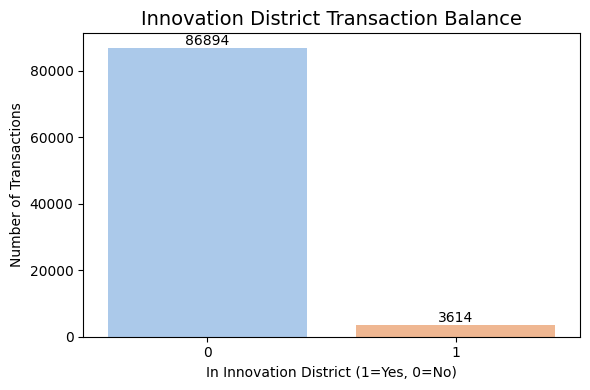

In [ ]:
# number of deals in Innovation District Vs. the rest of Beer-Sheva
def plot_innovation_balance(df, col='in_innovation_district'):
    plot_df = df.copy()
    plot_df[col] = pd.to_numeric(plot_df[col], errors='coerce')
    plot_df = plot_df.dropna(subset=[col])
    plot_df[col] = plot_df[col].astype(int)

    plt.figure(figsize=(6, 4))
    ax = sns.countplot(x=col, data=plot_df, palette="pastel")
    plt.title("Innovation District Transaction Balance", fontsize=14)
    plt.xlabel("In Innovation District (1=Yes, 0=No)")
    plt.ylabel("Number of Transactions")

    for p in ax.patches:
        count = int(p.get_height())
        ax.annotate(count, (p.get_x() + p.get_width() / 2., count),
                    ha='center', va='bottom', fontsize=10)
    plt.tight_layout()
    plt.show()

plot_innovation_balance(multi_city_df)

#### **3.3.2 Compare YEARBUILT Vs. BUILDINYEAR**

`building_year` and `year_built` looked like they might be duplicate fields; this compares them directly to decide whether to keep both, drop one, or reconcile mismatches.

In [ ]:
# create copy of rows contain 'buildingyear' and 'yearbuilt'
multi_city_df['building_year'] = pd.to_numeric(multi_city_df['building_year'], errors='coerce')
multi_city_df['year_built'] = pd.to_numeric(multi_city_df['year_built'], errors='coerce')
comparison_df = multi_city_df.dropna(subset=['building_year', 'year_built']).copy()

# compare and calculate difference
comparison_df['is_identical'] = comparison_df['building_year'] == comparison_df['year_built']
comparison_df['difference'] = comparison_df['building_year'] - comparison_df['year_built']

identical_count = comparison_df['is_identical'].sum()
different_count = len(comparison_df) - identical_count

print(f"=== Comparison BuildingYear & YearBuilt ===")
print(f"Comparables rows: {len(comparison_df)}")
print(f"Identical values: {identical_count}")
print(f"Different values: {different_count}")

# display rows with difference
if different_count > 0:
    print("\n Difference examples:")
    # present only relevant cols for the different rows
    df_diff = comparison_df[~comparison_df['is_identical']][['building_year', 'year_built', 'difference']]
    display(df_diff.head(10))
else:
    print("\n All values in the two cols identical for the checked rows.")

=== Comparison BuildingYear & YearBuilt ===
Comparables rows: 10535
Identical values: 0
Different values: 10535

 Difference examples:


,building_year,year_built,difference
587,1960.0,2008.0,-48.0
612,1980.0,2009.0,-29.0
1199,1963.0,2015.0,-52.0
1453,1980.0,2012.0,-32.0
1703,1970.0,2010.0,-40.0
1907,1960.0,2019.0,-59.0
1953,1970.0,2010.0,-40.0
2052,1980.0,2013.0,-33.0
2197,1960.0,2024.0,-64.0
2253,1980.0,2021.0,-41.0


### **3.4 Empty Cols Detection**

Drops columns that are 100% empty across all merged sources - usually happens when a field exists in one city's file but not another's.

In [ ]:
# remove completly empty cols
dataset_cleaned = multi_city_df.dropna(axis=1, how='all')

# print sample
print(f"Original cols: {multi_city_df.shape[1]}")
print(f"Cols after cleaning: {dataset_cleaned.shape[1]}")
dataset_cleaned.head()

Original cols: 51
Cols after cleaning: 51


,Name,NoteType,NoteType_1,OBJECTID,TARGET_FID,TARGET_FID_1,area_of_asset_sqm,building_year,change_trend_format,city,...,project_name,property_type,room_num,street,target_fid_identifier,type,x,y,year_built,_source_file
0,None,None,None,None,None,None,84.0,2023.0,None,באר שבע,...,None,דירה בבית קומות,3.0,תאנה,1.0,2.0,34.801537,31.231903,NaN,beer_sheva_original
1,None,None,None,None,None,None,59.6,1970.0,-8% ב 1.7 שנים,באר שבע,...,None,דירה בבית קומות,3.0,אלפסי,2.0,1.0,34.773613,31.256945,NaN,beer_sheva_original
2,None,None,None,None,None,None,50.6,1960.0,None,באר שבע,...,None,דירה בבית קומות,3.0,יוסף בן מתתיהו,4.0,1.0,34.800009,31.265929,NaN,beer_sheva_original
3,None,None,None,None,None,None,92.0,1998.0,31% ב 5.5 שנים,באר שבע,...,None,דירה בבית קומות,4.0,סתוי משה,3.0,1.0,34.767675,31.240088,NaN,beer_sheva_original
4,None,None,None,None,None,None,144.0,2000.0,None,באר שבע,...,None,דירה בבית קומות,5.0,קנדל הנרי,5.0,1.0,34.783234,31.245247,NaN,beer_sheva_original


### **3.5 Missing Values Profiling**

Full missing-value and dtype audit of every remaining column, auto-classified as categorical/numerical/boolean, used to decide what to drop or fix next.

In [ ]:
# create basic cols info function
def detailed_structure_analysis(df, name="Data", categorical_threshold=15):
    # create a table of basic data for each col
    summary = pd.DataFrame({
        'Column': df.columns,
        'Dtype': df.dtypes,
        'Missing Values': df.isnull().sum(),
        'Missing %': df.isnull().mean() * 100,
        'Unique Values': df.nunique()
    }).reset_index(drop=True)

    # automatic classify column type
    def classify_col(col, dtype, nunique):
        if pd.api.types.is_bool_dtype(dtype):
            return 'Boolean'
        elif pd.api.types.is_numeric_dtype(dtype):
            return 'Categorical' if nunique <= categorical_threshold else 'Numerical'
        elif pd.api.types.is_object_dtype(dtype) or pd.api.types.is_categorical_dtype(dtype):
            return 'Categorical'
        else:
            return 'Other'

    # clssify each row
    summary['Automatic Feature Type'] = [
        classify_col(col, row['Dtype'], row['Unique Values'])
        for col, row in zip(summary['Column'], summary.to_dict('records'))]

    # sort by % missing values
    summary = summary.sort_values(by='Missing %', ascending=False).reset_index(drop=True)

    print(f"======== {name.upper()} STRUCTURE ANALYSIS ========")
    display(summary)

detailed_structure_analysis(dataset_cleaned, name="Dataset")

======== DATASET STRUCTURE ANALYSIS ========


,Column,Dtype,Missing Values,Missing %,Unique Values,Automatic Feature Type
0,NoteType_1,object,808005,99.962638,1,Categorical
1,created_date_1,object,808005,99.962638,1,Categorical
2,created_user_1,object,808005,99.962638,1,Categorical
3,last_edited_date_1,object,808005,99.962638,1,Categorical
4,last_edited_user_1,object,808005,99.962638,1,Categorical
5,percentage,object,805448,99.646298,1231,Categorical
6,num_of_years,object,805163,99.611039,264,Categorical
7,NoteType,object,802074,99.228882,1,Categorical
8,Name,object,802074,99.228882,23,Categorical
9,created_date,object,802074,99.228882,4,Categorical


In [ ]:
# decide which cols to drop
threshold = 0.99
missing_pct = dataset_cleaned.isnull().mean()
cols_to_drop = missing_pct[missing_pct > threshold].index.tolist()

print(f"Cols to remove ({len(cols_to_drop)}):")
print(cols_to_drop)

dataset_cleaned = dataset_cleaned.drop(columns=cols_to_drop)
print(f"\n Cols left: {dataset_cleaned.shape[1]}")

Cols to remove (16):
['Name', 'NoteType', 'NoteType_1', 'OBJECTID', 'TARGET_FID', 'TARGET_FID_1', 'created_date', 'created_date_1', 'created_user', 'created_user_1', 'last_edited_date', 'last_edited_date_1', 'last_edited_user', 'last_edited_user_1', 'num_of_years', 'percentage']

 Cols left: 35


### **3.6 Sparse Rows Detection**

Drops rows that are mostly empty (>80% missing) - these carry too little information to be usable regardless of which columns survive.

In [ ]:
# identify almost empty rows (over 80% is missing)
row_missing_threshold = 80
row_missing_percent = dataset_cleaned.isnull().mean(axis=1) * 100

rows_before = len(dataset_cleaned)
dataset_cleaned = dataset_cleaned[row_missing_percent <= row_missing_threshold].copy()

rows_removed = rows_before - len(dataset_cleaned)
print(f"=== Clean empty rows (over {row_missing_threshold}% missing) ===")
print(f"-{rows_removed} rows removed.")
print(f"- New dataset contains (rows, cols): {dataset_cleaned.shape}")

=== Clean empty rows (over 80% missing) ===
-46916 rows removed.
- New dataset contains (rows, cols): (761391, 35)


### **3.7 Automatic Feature Classification**

Automatically splits columns into categorical vs. numerical based on dtype and cardinality, as a starting point that gets manually refined in Part 4.

#### **3.7.1 Automatic Categorical Classification**

A column is flagged categorical if it's non-numeric, or numeric with few unique values.

In [ ]:
# Identify categorical columns in a dataframe based on data type and cardinality
def get_categorical_columns(df, threshold=15):
    cat_cols = []
    # Iterate over all columns in the dataframe
    for col in df.columns:
        # If the column is explicitly categorical (object, bool, or category), add to list
        if df[col].dtype in ['object', 'bool', 'category']:
            cat_cols.append(col)
        # If the column is numeric but has a limited number of unique values, treat it as categorical
        elif pd.api.types.is_numeric_dtype(df[col]):
            if df[col].nunique() <= threshold:
                cat_cols.append(col)
    return cat_cols

cat_cols = get_categorical_columns(dataset_cleaned)

print("Categorical columns:")
for col in cat_cols:
    print("-", col)

Categorical columns:
- area_of_asset_sqm
- change_trend_format
- city
- deal_amount
- deal_date
- deal_date_time
- deal_year
- floor
- floors_in_building
- full_adress
- gush
- gush_copy_parcel
- gush_helka
- in_innovation_district
- join_count
- key_value_identifier
- negative_trend
- neighborhood
- new_project
- not_full_adress
- object_id_identifier
- polygon_id
- price_per_sqm
- price_percentage_per_year
- project_name
- property_type
- room_num
- street
- target_fid_identifier
- type
- x
- y
- _source_file


#### **3.7.2 Automatic Numeric Classification**

Everything not flagged as categorical is treated as numeric by default.

In [ ]:
# Identify numerical columns by excluding known categorical columns
def get_numerical_columns(df, cat_cols):
    return [col for col in df.columns if col not in cat_cols]

num_cols = get_numerical_columns(dataset_cleaned, cat_cols)

print("Numerical columns:")
for col in num_cols:
    print("-", col)

Numerical columns:
- building_year
- year_built


### **3.8 Preliminary Visualizations**

First-pass, unfiltered visual and statistical overview of every column, before any manual fixes - useful for spotting obvious data-quality issues.

#### **3.8.1 Numeric Cols - Preliminary Statistics**

`.describe()` summary for every numeric column.

In [ ]:
# calculate count, mean, std, min-max,
def statistical_summary(df, name="Data"):
    print(f"======== {name.upper()} STATISTICAL SUMMARY ========")
    print("\n--- Numerical Features ---")
    display(df.describe().T)

statistical_summary(dataset_cleaned, name="Dataset")

======== DATASET STATISTICAL SUMMARY ========

--- Numerical Features ---


,count,mean,std,min,25%,50%,75%,max
building_year,744377.0,1979.990298,82.908474,0.0,1967.0,1980.0,2002.0,2034.0
year_built,10535.0,2017.788420,5.108630,2008.0,2014.0,2018.0,2022.0,2033.0


#### **3.8.2 Numeric Cols - Preliminary Histograms**

Distribution shape for each numeric column - look for implausible values, heavy skew, or multi-modal patterns that hint at mixed units or data errors.

======= DATA – NUMERIC DISTRIBUTIONS =======


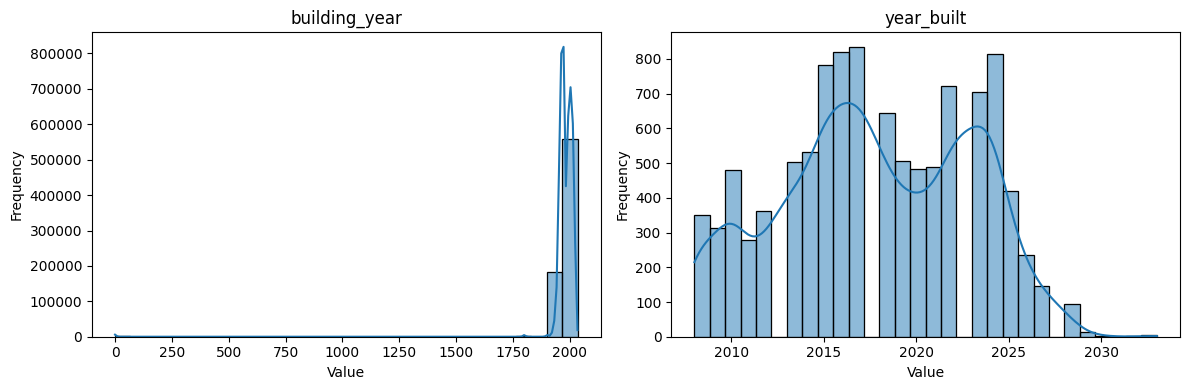

In [ ]:
# create distribution histogram for numerical features
def plot_numeric_distributions(df, bins=30, name="Data"):
    numeric_cols = df.select_dtypes(include=['number']).columns
    num_plots = len(numeric_cols)

    print(f"======= {name.upper()} – NUMERIC DISTRIBUTIONS =======")

    ncols = 2
    nrows = math.ceil(num_plots / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 4 * nrows))
    axes = axes.flatten()

    # create histograms
    for i, col in enumerate(numeric_cols):
        sns.histplot(df[col].dropna(), bins=bins, ax=axes[i], kde=True)
        axes[i].set_title(col)
        axes[i].set_xlabel("Value")
        axes[i].set_ylabel("Frequency")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_numeric_distributions(dataset_cleaned)

#### **3.8.3 Categoric Cols - Preliminary Statistics & Histograms**

Top categories per categorical column - useful for spotting inconsistent labels (e.g. the same street spelled two ways) before the targeted fixes in Part 4.

======= DATASET CATEGORICAL COUNTS =======




In [ ]:
# create distribution histogram for categorical features
def plot_categorical_counts(df, max_categories=10, name="Data"):
    cat_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns
    num_plots = len(cat_cols)

    fixed_name = get_display(str(name))
    print(f"======= {fixed_name.upper()} CATEGORICAL COUNTS =======")

    ncols = 2
    nrows = math.ceil(num_plots / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 6 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(cat_cols):
        counts = df[col].value_counts(dropna=False).head(max_categories)
        labels = [get_display(textwrap.fill(str(label), width=12)) for label in counts.index]
        sns.barplot(x=labels, y=counts.values, ax=axes[i])
        fixed_col = get_display(str(col))
        axes[i].set_title(f"{fixed_col} – Top {max_categories}", fontsize=11)
        axes[i].set_ylabel("Count")
        axes[i].set_xlabel("Category")
        axes[i].tick_params(axis='x', rotation=45)

    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_categorical_counts(dataset_cleaned, name="dataset")

# **PART 4: Data Cleaning & Preprocessing**

Targeted cleaning: manual column classification, recovering/dropping missing price labels, fixing known messy columns (property type, floor, room count, etc.), and removing outliers.

### **4.1. Manual Variables Classification**

Overrides the automatic classification from Part 3 with domain knowledge - flags ID/location columns as non-features, and force-casts specific columns to numeric/categorical based on what they actually represent.

In [ ]:
# list of non-features cols (random identifier etc.) that won't be analized but will remain in the dataset
not_features = ['deal_date_time',
                'gush',
                'gush_copy_parcel',
                'gush_helka',
                'join_count',
                'key_value_identifier',
                'num_of_years',
                'object_id_identifier',
                'polygon_id',
                'target_fid_identifier',
                'Name',
                'NoteType',
                'NoteType_1',
                'created_user',
                'created_user_1',
                'last_edited_user',
                'last_edited_user_1',
                'OBJECTID',
                'TARGET_FID',
                'TARGET_FID_1',
                'created_date',
                'created_date_1',
                'deal_date',
                'last_edited_date',
                'last_edited_date_1',
                'num_of_years',
                'percentage',
                'x',
                'y',
                '_source_file']

num_cols = [col for col in num_cols if col not in not_features]
cat_cols = [col for col in cat_cols if col not in not_features]

label_1 = 'price_per_sqm'
label_2 = 'deal_amount'

# define cols to manual classification
fix_to_categorical = []
fix_to_numeric = ['area_of_asset_sqm', 'deal_amount', 'floors_in_building', 'room_num', 'building_year', 'year_built']

for col in fix_to_categorical:
    if col in dataset_cleaned.columns:
        dataset_cleaned[col] = dataset_cleaned[col].astype('category')
        if col in num_cols: num_cols.remove(col)
        if col not in cat_cols and col not in not_features:
            cat_cols.append(col)

for col in fix_to_numeric:
    if col in dataset_cleaned.columns:
        dataset_cleaned[col] = pd.to_numeric(dataset_cleaned[col], errors='coerce')
        if col in cat_cols: cat_cols.remove(col)
        if col not in num_cols and col not in not_features:
            num_cols.append(col)

# print updated classification
print(f"Fields left in daset but are not features: {not_features}")
print(f"Total numeric cols to analyze: {len(num_cols)}")
print(num_cols)
print(f"Total categorical cols to analyze: {len(cat_cols)}")
print(cat_cols)


Fields left in daset but are not features: ['deal_date_time', 'gush', 'gush_copy_parcel', 'gush_helka', 'join_count', 'key_value_identifier', 'num_of_years', 'object_id_identifier', 'polygon_id', 'target_fid_identifier', 'Name', 'NoteType', 'NoteType_1', 'created_user', 'created_user_1', 'last_edited_user', 'last_edited_user_1', 'OBJECTID', 'TARGET_FID', 'TARGET_FID_1', 'created_date', 'created_date_1', 'deal_date', 'last_edited_date', 'last_edited_date_1', 'num_of_years', 'percentage', 'x', 'y', '_source_file']
Total numeric cols to analyze: 6
['building_year', 'year_built', 'area_of_asset_sqm', 'deal_amount', 'floors_in_building', 'room_num']
Total categorical cols to analyze: 16
['change_trend_format', 'city', 'deal_year', 'floor', 'full_adress', 'in_innovation_district', 'negative_trend', 'neighborhood', 'new_project', 'not_full_adress', 'price_per_sqm', 'price_percentage_per_year', 'project_name', 'property_type', 'street', 'type']


### **4.2. Filtering Missing Labels**

Since `price_per_sqm` and `deal_amount` are the target variables, rows missing both are unusable and need to be identified/handled before modeling.

#### **4.2.1 removing Missing Labels**

Breaks down how much of the missing-label problem is concentrated in specific source files or cities, to check whether it's a systemic issue with one data source.

In [ ]:
# breakdown of missing prices by source file and city
print("=== חסרים לפי קובץ מקור ===")
print(multi_city_df.groupby('_source_file')[['deal_amount', 'price_per_sqm']].apply(
    lambda g: pd.Series({
        'total_rows': len(g),
        'missing_deal_amount': g['deal_amount'].isna().sum(),
        'missing_price_per_sqm': g['price_per_sqm'].isna().sum(),
        'pct_missing_amount': f"{g['deal_amount'].isna().mean():.1%}",
        'pct_missing_price_sqm': f"{g['price_per_sqm'].isna().mean():.1%}",
    })
).to_string())

print("\n=== חסרים לפי עיר ===")
if 'city' in multi_city_df.columns:
    print(multi_city_df.groupby('city')[['deal_amount', 'price_per_sqm']].apply(
        lambda g: pd.Series({
            'total_rows': len(g),
            'missing_deal_amount': g['deal_amount'].isna().sum(),
            'pct_missing': f"{g['deal_amount'].isna().mean():.1%}",
        })
    ).to_string())

=== חסרים לפי קובץ מקור ===
                                                   total_rows  missing_deal_amount  missing_price_per_sqm pct_missing_amount pct_missing_price_sqm
_source_file                                                                                                                                      
beer_sheva_original                                     71889                23459                  23820              32.6%                 33.1%
עותק של tamnon_with_xy_ariel_with_innovation.xlsx       65535                23459                  23814              35.8%                 36.3%
שליש ראשון - גיליון1.csv                               230606                34121                  36263              14.8%                 15.7%
שליש שלישי - גיליון1.csv                               229112                    0                   6191               0.0%                  2.7%
שליש שני - גיליון1.csv                                 211165                    0        

In [ ]:
# breakdown of missing prices by source file and city
print("=== Empty labels ===")
source_missing_df = multi_city_df.groupby('_source_file')[['deal_amount', 'price_per_sqm']].apply(
    lambda g: pd.Series({
        'total_rows': len(g),
        'missing_deal_amount': g['deal_amount'].isna().sum(),
        'missing_price_per_sqm': g['price_per_sqm'].isna().sum(),
        'pct_missing_amount': f"{g['deal_amount'].isna().mean():.1%}",
        'pct_missing_price_sqm': f"{g['price_per_sqm'].isna().mean():.1%}",
    })
)

# show as a table
display(source_missing_df)

print("\n=== חסרים לפי עיר ===")
if 'city' in multi_city_df.columns:
    city_missing_df = multi_city_df.groupby('city')[['deal_amount', 'price_per_sqm']].apply(
        lambda g: pd.Series({
            'total_rows': len(g),
            'missing_deal_amount': g['deal_amount'].isna().sum(),
            'pct_missing': f"{g['deal_amount'].isna().mean():.1%}",
        })
    )
    # show as a table
    display(city_missing_df)

=== Empty labels ===


,total_rows,missing_deal_amount,missing_price_per_sqm,pct_missing_amount,pct_missing_price_sqm
_source_file,,,,,
beer_sheva_original,71889,23459,23820,32.6%,33.1%
עותק של tamnon_with_xy_ariel_with_innovation.xlsx,65535,23459,23814,35.8%,36.3%
שליש ראשון - גיליון1.csv,230606,34121,36263,14.8%,15.7%
שליש שלישי - גיליון1.csv,229112,0,6191,0.0%,2.7%
שליש שני - גיליון1.csv,211165,0,2634,0.0%,1.2%



=== חסרים לפי עיר ===


,total_rows,missing_deal_amount,pct_missing
city,,,
city_name,1,1,100.0%
אשדוד,34120,34120,100.0%
אשקלון,22776,0,0.0%
באר שבע,84154,2,0.0%
בית שמש,13149,0,0.0%
בני ברק,24124,0,0.0%
בת ים,29157,0,0.0%
הרצלייה,18385,0,0.0%
חדרה,18356,0,0.0%


#### **4.2.2 removing Missing Labels**

Recovers whichever of `deal_amount` / `price_per_sqm` can be derived from the other (using `area_of_asset_sqm`), then drops only the rows where neither label can be recovered.

In [ ]:
print("=== Before fixing ===")
print(f"Total rows: {len(dataset_cleaned):,}")

# recover deal_amount from price_per_sqm × area where possible
mask_recover_deal = (
    dataset_cleaned['deal_amount'].isna() &
    dataset_cleaned['price_per_sqm'].notna() &
    dataset_cleaned['area_of_asset_sqm'].notna()
)
dataset_cleaned.loc[mask_recover_deal, 'deal_amount'] = (
    dataset_cleaned.loc[mask_recover_deal, 'price_per_sqm'] *
    dataset_cleaned.loc[mask_recover_deal, 'area_of_asset_sqm']
)
print(f"Recovered deal_amount: {mask_recover_deal.sum():,}")

# recover price_per_sqm from deal_amount / area where possible
mask_recover_sqm = (
    dataset_cleaned['price_per_sqm'].isna() &
    dataset_cleaned['deal_amount'].notna() &
    dataset_cleaned['area_of_asset_sqm'].notna()
)
dataset_cleaned.loc[mask_recover_sqm, 'price_per_sqm'] = (
    dataset_cleaned.loc[mask_recover_sqm, 'deal_amount'] /
    dataset_cleaned.loc[mask_recover_sqm, 'area_of_asset_sqm']
)
print(f"Recovered price_per_sqm: {mask_recover_sqm.sum():,}")

# now drop only rows where BOTH labels are still missing (truly unrecoverable)
truly_missing = (
    dataset_cleaned['deal_amount'].isna() &
    dataset_cleaned['price_per_sqm'].isna()
)
print(f"Rows without price (to remove): {truly_missing.sum():,}")

dataset_cleaned = dataset_cleaned[~truly_missing].copy()
print(f"\nשורות שנותרו: {len(dataset_cleaned):,}")
print(f"חסרים ב-price_per_sqm: {dataset_cleaned['price_per_sqm'].isna().sum():,}")
print(f"חסרים ב-deal_amount: {dataset_cleaned['deal_amount'].isna().sum():,}")

=== Before fixing ===
Total rows: 761,391
Recovered deal_amount: 2
Recovered price_per_sqm: 0
Rows without price (to remove): 34,121

שורות שנותרו: 727,270
חסרים ב-price_per_sqm: 11,685
חסרים ב-deal_amount: 0


In [ ]:
# Filter only the rows where price_per_sqm is still missing
unresolved_prices = dataset_cleaned[dataset_cleaned['price_per_sqm'].isna()]

# Check how many of them are missing the area
missing_area_count = unresolved_prices['area_of_asset_sqm'].isna().sum()

print(f"Out of {len(unresolved_prices):,} unresolved prices, {missing_area_count:,} are missing area_of_asset_sqm.")

Out of 11,685 unresolved prices, 11,685 are missing area_of_asset_sqm.


### **4.3. Variables Fixation**

Column-by-column cleanup of specific messy fields identified during EDA - free-text categories, floor numbers written as Hebrew words, numeric codes, etc.

#### **4.3.2 property_type - Fixation**

Collapses dozens of raw Hebrew property-type labels into a small set of consistent categories (residential, commercial, agricultural, etc.) using an explicit mapping dictionary. Any unmapped value is flagged in the output rather than silently dropped - check that printout on a new dataset for categories the dictionary doesn't cover yet.

In [ ]:
# 1. הגדרת המיפוי (הקפידי להשתמש בשם העמודה המדויק כפי שהוא מופיע ב-dataset_cleaned)
property_mapping = {
    'בית בודד': 'מגורים', 'בית פרטי': 'מגורים', 'דופלקס': 'מגורים',
    'דירה': 'מגורים', 'דירה בבית קומות': 'מגורים', 'דירת גג': 'מגורים',
    'דירת גג (פנטהאוז)': 'מגורים', 'דירת גן': 'מגורים', 'דירת נופש': 'מגורים',
    'חד משפחתי (וילה)': 'מגורים', 'מגורים': 'מגורים', 'מיני פנטהאוז': 'מגורים',
    'קוטג\' דו משפחתי': 'מגורים', 'קוטג\' חד משפחתי': 'מגורים', 'קוטג\' טורי': 'מגורים',
    'במשק חקלאי-נחלה': 'חקלאות',
    'בניני ציבור': 'ציבורי',
    'חנות': 'עסקים', 'מלאכה': 'עסקים', 'משרד': 'עסקים', 'עסק': 'עסקים',
    'תעשיה': 'עסקים', 'מסחרי + משרדים': 'עסקים', 'תחנת דלק': 'עסקים',
    'מלונאות': 'תיירות',
    'מסחרי + מגורים': 'מסחרי + מגורים',
    'קרקע למגורים': 'קרקע למגורים',
    'אחר': 'אחר או לא ידוע', 'nan': 'אחר או לא ידוע', 'חניה': 'אחר או לא ידוע',
    'ללא תיכנון': 'אחר או לא ידוע', 'מחסנים': 'אחר או לא ידוע', 'קומבינציה': 'אחר או לא ידוע',
}

# 2. יצירת העמודה החדשה (אני משתמש ב-property_type, אם השם בטבלה שלך אחר, עדכני אותו כאן)
# ודאי ששם העמודה הוא בדיוק מה שמופיע ב-dataset_cleaned.columns
source_col = 'property_type'
target_col = 'property_category'

dataset_cleaned[target_col] = (
    dataset_cleaned[source_col]
    .astype(str)
    .str.strip()
    .map(property_mapping)
    .fillna('חסרה קטגוריה')
)

# 3. עדכון רשימת הקטגוריות הגלובלית
if target_col not in cat_cols:
    cat_cols.append(target_col)
    print(f"העמודה '{target_col}' התווספה לרשימת cat_cols! ✅")

# 4. פילוח והצגת ערכים חסרים (חסין לשגיאות)
print("\n" + "="*40)
print("פילוח הקטגוריות החדשות:")
print("="*40)
print(dataset_cleaned[target_col].value_counts(dropna=False))

# בדיקת ערכים חסרים
missing_rows = dataset_cleaned[dataset_cleaned[target_col] == 'חסרה קטגוריה']
if not missing_rows.empty:
    print(f"\n--- נמצאו {len(missing_rows)} שורות שזקוקות לתיקון מיפוי ---")
    print("הערכים המקוריים שחסרים במילון:")
    print(missing_rows[source_col].astype(str).str.strip().value_counts())
else:
    print("\n✅ מעולה! כל הערכים מופו בהצלחה.")

העמודה 'property_category' התווספה לרשימת cat_cols! ✅

פילוח הקטגוריות החדשות:
property_category
מגורים            609775
אחר או לא ידוע     78016
עסקים              28883
קרקע למגורים        6329
חסרה קטגוריה        3358
ציבורי               448
תיירות               325
מסחרי + מגורים       133
חקלאות                 3
Name: count, dtype: int64

--- נמצאו 3358 שורות שזקוקות לתיקון מיפוי ---
הערכים המקוריים שחסרים במילון:
property_type
None                         2367
לא ידוע                       718
דיור מוגן                      52
קבוצת רכישה - קרקע מגורים      52
אופציה                         45
משרדים + מגורים                44
בית אבות                       22
מבנים חקלאיים                  18
חלוקה/יחוד דירות               12
ניוד זכויות בניה               10
קבוצת רכישה - קרקע מסחרי        9
מלונאות ונופש                   5
קרקע ל8- יחידות ומעלה           2
פעולה באיגוד                    1
לא מעובדת                       1
Name: count, dtype: int64


#### **4.3.3 floor - Fixation**

The raw `floor` field mixes digits, Hebrew ordinal words ('קרקע', 'שלישי', etc.), and combined values; this parses it into two clean numeric features: `floor_min` and `num_floors_in_asset`.

In [ ]:
print("=== שלב 1: בדיקת התפלגות הערכים הנוכחית (Value Counts) ===")
print(dataset_cleaned['floor'].value_counts(dropna=False))

print("\n=== שלב 2: בדיקת כמות הערכים החסרים שנוצרו ===")
nan_count = dataset_cleaned['floor'].isna().sum()
print(f"כמות ערכי NaN (חסרים) בעמודה כרגע: {nan_count}")

# שלב 3: בדיקה מול הדאטה הגולמי המקורי (אם הוא עדיין טעון אצלך בזיכרון, למשל תחת השם df או dataset)
# נסי להריץ את זה כדי לראות איך זה היה נראה לפני הניקוי:
try:
    # נניח שהדאטה המקורי שלך נקרא 'dataset' או 'df_raw' - שנה את השם בהתאם במידת הצורך
    if 'dataset' in globals():
        print("\n=== שלב 3: הצצה לעמודת floor בדאטה המקורי ===")
        print(dataset['floor'].astype(str).str.strip().value_counts().head(15))
    elif 'df' in globals():
        print("\n=== שלב 3: הצצה לעמודת floor בדאטה המקורי ===")
        print(df['floor'].astype(str).str.strip().value_counts().head(15))
except Exception as e:
    print(f"\nלא ניתן לגשת לדאטה המקורי: {e}")

=== שלב 1: בדיקת התפלגות הערכים הנוכחית (Value Counts) ===
floor
ראשונה             143156
שניה               117728
שלישית              96899
רביעית              63664
NaN                 48565
                    ...  
שביעית  ושמינית         1
ראשונה ובניים           1
קרקע במספר 5            1
שניה במס' 7             1
קרקע במספר 8            1
Name: count, Length: 2607, dtype: int64

=== שלב 2: בדיקת כמות הערכים החסרים שנוצרו ===
כמות ערכי NaN (חסרים) בעמודה כרגע: 52977

=== שלב 3: הצצה לעמודת floor בדאטה המקורי ===
floor
nan          27870
ראשונה        9028
שניה          6242
שלישית        5665
רביעית        3778
קרקע          3334
חמישית        1654
שישית         1235
שביעית         903
שמינית         772
תשיעית         475
עשירית         302
אחת עשרה       257
שלוש עשרה      231
שתים עשרה      224
Name: count, dtype: int64


In [ ]:
def extract_floor_features_v4(val):
    if pd.isna(val) or str(val).lower() == 'nan' or str(val).lower() == 'none':
        return pd.Series({'floor_min': np.nan, 'num_floors_in_asset': np.nan})

    # 1. ניקוי ראשוני: הפיכת תווים מפרידים לרווחים וסטנדרטיזציה
    val = str(val).lower().replace('\u200e', '').replace('+', ' ').replace(',', ' ').replace('/', ' ').replace('-', ' ')

    # מיפוי מורחב לכל המקרים שציינת
    mapping = {
        'מרתף': -1, 'קרקע': 0, 'ק.': 0, 'יציע': 0, 'גלריה': 0, 'עלית גג': 99, # 99 יטופל כחריג
        'ראשון': 1, 'ראשונה': 1, 'אחת': 1, 'אחד': 1,
        'שני': 2, 'שניה': 2, 'שנייה': 2, 'שתים': 2, 'שתיים': 2,
        'שלישי': 3, 'שלישית': 3, 'שלוש': 3,
        'רביעי': 4, 'רביעית': 4, 'ארבע': 4,
        'חמישי': 5, 'חמישית': 5, 'חמש': 5,
        'שישי': 6, 'שישית': 6, 'שש': 6,
        'שביעי': 7, 'שביעית': 7, 'שבע': 7,
        'שמיני': 8, 'שמינית': 8, 'שמונה': 8,
        'תשיעי': 9, 'תשיעית': 9, 'תשע': 9,
        'עשירי': 10, 'עשירית': 10, 'עשר': 10,
        'אחד עשרה': 11, 'אחת עשרה': 11,
        'שתים עשרה': 12, 'שנים עשר': 12,
        'שלוש עשרה': 13,
        'ארבע עשרה': 14,
        'חמש עשרה': 15,
        'שש עשרה': 16,
        'שבע עשרה': 17,
        'שמונה עשרה': 18,
        'תשע עשרה': 19,
        'עשרים': 20, 'עשרים ואחת': 21, 'עשרים ושתיים': 22, 'עשרים ושלוש': 23,
        'עשרים וארבע': 24, 'עשרים וחמש': 25, 'עשרים ושש': 26, 'עשרים ושבע': 27,
        'עשרים ושמונה': 28, 'עשרים ותשע': 29, 'שלושים': 30
    }

    found_nums = set()

    # 2. חילוץ מספרים דיגיטליים (כמו 'קומה 3' -> 3)
    digits = re.findall(r'\d+', val.replace('.0', ''))  # or check val.replace('.','',1).isdigit() and parse as int directly
    for d in digits:
        found_nums.add(int(d))

    # 3. חילוץ מילים מתוך המיפוי
    for text, num in mapping.items():
        if text in val:
            found_nums.add(num)

    # ניקוי ערכים לא הגיוניים (כמו 99 למי שרוצה)
    final_nums = {n for n in found_nums if n < 90}

    if not final_nums:
        return pd.Series({'floor_min': np.nan, 'num_floors_in_asset': np.nan})

    return pd.Series({
        'floor_min': min(final_nums),
        'num_floors_in_asset': len(final_nums)
    })

# הרצה על הדאטהסט
new_features = dataset_cleaned['floor'].apply(extract_floor_features_v4)
dataset_cleaned[['floor_min', 'num_floors_in_asset']] = new_features

In [ ]:
for col in ['floor_min', 'num_floors_in_asset']:
    if col not in num_cols:
        num_cols.append(col)

# הסרת העמודה 'floor' מרשימת ה-cat_cols
cat_cols = [col for col in cat_cols if col != 'floor']

#### **4.3.5 type - Fixation**


`type` is a numeric-looking code column of unclear meaning (see the 'UNKNOWN' flag in the data dictionary above). This only standardizes its formatting (removes trailing '.0', labels true missing values) without asserting what the codes mean.

In [ ]:
# 1. ניקוי והמרת ערכי העמודה 'type' לטקסט נקי ללא רווחים מיותרים
type_series = dataset_cleaned['type'].astype(str).str.strip()

# 2. חישוב כמות המופעים המלאה (ממוין אוטומטית מהנפוץ ביותר לפחות נפוץ)
type_counts = type_series.value_counts()

print(f"--- פילוח ערכים ממוין בעמודת type ({len(type_counts)} ערכים ייחודיים) ---\n")

# 3. הדפסה בפורמט המבוקש: מספר סידורי. ערך (כמות מופעים)
for i, (val_name, count) in enumerate(type_counts.items(), 1):
    # מציג פסיקים כמפרידי אלפים בתוך הסוגריים לטובת קריאות נוחה
    print(f"{i}. {val_name} ({count:,})")

# 4. הדפסת שורת סיכום גלובלית
print("\n" + "=" * 50)
print(f"סה\"כ שורות מעובדות בעמודה: {type_counts.sum():,}")
print("=" * 50)

--- פילוח ערכים ממוין בעמודת type (5 ערכים ייחודיים) ---

1. 1 (630,150)
2. 1.0 (82,954)
3. 2 (6,612)
4. None (6,354)
5. 2.0 (1,200)

סה"כ שורות מעובדות בעמודה: 727,270


In [ ]:
# 1. פונקציה שמורידה את ה-'.0' והופכת את הערך למספר שלם בפורמט טקסט
def clean_type_to_string(val):
    if pd.isna(val) or str(val).strip().lower() in ['nan', 'none']:
        return "לא ידוע"
    # הפיכה ל-float ואז ל-int מורידה את ה-.0 בצורה בטוחה
    return str(int(float(val)))

# 2. החלת השינוי על עמודת type
dataset_cleaned['type'] = dataset_cleaned['type'].apply(clean_type_to_string)

# 3. הוספת העמודה 'type' לרשימת המשתנים הקטגוריאליים (cat_cols) במידה ואינה שם
if 'type' not in cat_cols:
    cat_cols.append('type')
    print("העמודה 'type' התווספה בהצלחה לרשימת cat_cols! ✅")
else:
    print("העמודה 'type' כבר קיימת ברשימת cat_cols.")

# 4. הדפסת הפילוח החדש, הנקי והעגול בפורמט המבוקש
print("\n=== פילוח מעודכן ועגול של עמודת type ===")
type_counts = dataset_cleaned['type'].value_counts()
for i, (type_val, count) in enumerate(type_counts.items(), 1):
    print(f"{i}. סוג {type_val} ({count:,})")

העמודה 'type' כבר קיימת ברשימת cat_cols.

=== פילוח מעודכן ועגול של עמודת type ===
1. סוג 1 (713,104)
2. סוג 2 (7,812)
3. סוג לא ידוע (6,354)


#### **4.3.6 street - Fixation**

Exploratory check for street names that may be duplicated due to word-order differences (e.g. two words swapped). This cell only detects candidates for review - it does not automatically merge them.

In [ ]:
# 1. חישוב כמות המופעים לכל רחוב
# filter to Beer Sheva only
bs_data = dataset_cleaned[dataset_cleaned['city'] == 'באר שבע']
street_counts = bs_data['street'].value_counts()

# 2. הגדרת תצוגה מלאה ב-Colab כדי שלא יקטע את הרשימה באמצע
pd.set_option('display.max_rows', None)

print(f"--- בעיר באר-שבע יש סה\"כ {len(street_counts)} רחובות ייחודיים ---\n")

# 4. החזרת הגדרת התצוגה למצב רגיל
pd.reset_option('display.max_rows')

# 5. בדיקה קטנה של ערכים חסרים בשדה הרחוב
missing_streets = bs_data['street'].isna().sum()
if missing_streets > 0:
    print(f"\nשימי לב: ישנן {missing_streets} שורות שבהן שם הרחוב חסר (NaN).")

--- בעיר באר-שבע יש סה"כ 804 רחובות ייחודיים ---



In [ ]:
# 1. יצירת רשימה של רחובות ייחודיים (ללא NaN)
unique_streets = [s for s in bs_data['street'].unique() if pd.notna(s)]

# 2. יצירת מילון של "שמות מנורמלים"
# אנחנו מפרקים כל שם למילים, ממיינים אותן ומחברים חזרה
normalized_streets = {}
for street in unique_streets:
    # ניקוי בסיסי: הורדת רווחים והפיכה למילים
    words = tuple(sorted(str(street).strip().split()))
    if words not in normalized_streets:
        normalized_streets[words] = []
    normalized_streets[words].append(street)

# 3. סינון למקרים שבהם לאותו "נרמול" יש יותר משם מקורי אחד
duplicates = {k: v for k, v in normalized_streets.items() if len(v) > 1}

print(f"--- בדיקת שמות רחובות הפוכים או כפולים ---")
if not duplicates:
    print("לא נמצאו שמות הפוכים מובהקים.")
else:
    print(f"נמצאו {len(duplicates)} קבוצות של רחובות עם שמות דומים/הפוכים:\n")
    for words, originals in duplicates.items():
        print(f"השם המנורמל: {' '.join(words)}")
        print(f"מופיע בדאטה כ: {originals}")

        # הצגת כמות מופעים לכל וריאציה (כדי להחליט למי להצמיד)
        counts = dataset_cleaned[dataset_cleaned['street'].isin(originals)]['street'].value_counts()
        print("פירוט מופעים:")
        print(counts)
        print("-" * 30)

# בונוס: הדפסת כמות הרחובות הכללית לבדיקת יחס
print(f"\nסה\"כ רחובות ייחודיים בדאטה לפני איחוד: {len(unique_streets)}")

--- בדיקת שמות רחובות הפוכים או כפולים ---
לא נמצאו שמות הפוכים מובהקים.

סה"כ רחובות ייחודיים בדאטה לפני איחוד: 804


#### **4.3.7 room_num - Fixation**

Rounds raw room counts to the nearest half (0.5), since real-estate listings commonly use half-rooms (e.g. 3.5-room apartments) and the raw values sometimes have noisy precision.

In [ ]:
def round_to_nearest_half(val):
    if pd.isna(val) or str(val).lower() == 'nan':
        return np.nan
    try:
        # ניקוי תווים לא רצויים במידה ויש (כמו רווחים)
        num = float(str(val).strip())
        # נוסחת העיגול ל-0.5 הקרוב ביותר
        return round(num * 2) / 2
    except (ValueError, TypeError):
        return np.nan

# 1. דריסה של עמודה קודמת אם קיימת
if 'room_num_cleaned' in dataset_cleaned.columns:
    dataset_cleaned = dataset_cleaned.drop(columns=['room_num_cleaned'])

# 2. יצירת העמודה המנורמלת והמרתה ל-Float (כי חצאי חדרים הם עשרוניים)
dataset_cleaned['room_num_cleaned'] = dataset_cleaned['room_num'].apply(round_to_nearest_half)

# 3. עדכון רשימת העמודות הנומריות (num_cols)
if 'room_num_cleaned' not in num_cols:
    num_cols.append('room_num_cleaned')

# 4. הצגת כל הווריאציות ללא קיצור (146 שורות או כמה שיש)
print(f"--- הצגת המיפוי המלא של room_num (מקור מול עיגול ל-0.5) ---")
pd.set_option('display.max_rows', None)

# יצירת טבלת המרה ייחודית
rooms_map = dataset_cleaned[['room_num', 'room_num_cleaned']].drop_duplicates().sort_values('room_num')
display(rooms_map)

# 5. הדפסת שורת סיכום של ערכים ייחודיים
unique_count = dataset_cleaned['room_num_cleaned'].nunique()
print("\n" + "="*50)
print(f"after the change there are {unique_count} unique values in room_num_cleaned col.")
print("="*50)

pd.reset_option('display.max_rows')

--- הצגת המיפוי המלא של room_num (מקור מול עיגול ל-0.5) ---


,room_num,room_num_cleaned
757,1.0,1.0
1643,1.5,1.5
21,2.0,2.0
26708,2.3,2.5
16,2.5,2.5
582231,2.7,2.5
0,3.0,3.0
6,3.5,3.5
468955,3.6,3.5
3,4.0,4.0



after the change there are 25 unique values in room_num_cleaned col.


### **4.4. Feature List Validation & Exclusion (Dropping Dates/IDs)**

Final review of the numeric/categorical column lists — drops fields superseded by their cleaned versions (e.g. raw `floor`/`room_num`) or that are dates/IDs never meant to be modeling features. Also extracts `deal_month`/`deal_quarter` from the deal date.

In [ ]:
# הדפסת העמודות הנומריות
print(f"--- Numeric Columns ({len(num_cols)}) ---")
for col in num_cols:
    print(f"- {col}")

print("\n" + "="*30 + "\n")

# הדפסת העמודות הקטגוריאליות
print(f"--- Categorical Columns ({len(cat_cols)}) ---")
for col in cat_cols:
    print(f"- {col}")

print("\n" + "="*30 + "\n")

# עמודות שלא שויכו לאף קבוצה
uncategorized = [col for col in dataset_cleaned.columns if col not in num_cols and col not in cat_cols]
print(f"--- Uncategorized Columns ({len(uncategorized)}) ---")
for col in uncategorized:
    print(f"- {col}")

--- Numeric Columns (9) ---
- building_year
- year_built
- area_of_asset_sqm
- deal_amount
- floors_in_building
- room_num
- floor_min
- num_floors_in_asset
- room_num_cleaned


--- Categorical Columns (16) ---
- change_trend_format
- city
- deal_year
- full_adress
- in_innovation_district
- negative_trend
- neighborhood
- new_project
- not_full_adress
- price_per_sqm
- price_percentage_per_year
- project_name
- property_type
- street
- type
- property_category


--- Uncategorized Columns (14) ---
- deal_date
- deal_date_time
- floor
- gush
- gush_copy_parcel
- gush_helka
- join_count
- key_value_identifier
- object_id_identifier
- polygon_id
- target_fid_identifier
- x
- y
- _source_file


In [ ]:
# 1. הגדרת רשימות עמודות להסרה (כאן תכתבי את השמות המדויקים)
cols_to_remove_from_numeric = ['percentage', 'deal_date', 'floor', 'room_num']
cols_to_remove_from_categorical = ['full_adress', 'not_full_adress', 'property_type']

# 2. סינון רשימת העמודות הנומריות (num_cols)
# אנחנו מייצרים רשימה חדשה שכוללת רק את מה שלא נמצא ברשימת ההסרה
num_cols_final = [col for col in num_cols if col not in cols_to_remove_from_numeric]

# 3. סינון רשימת העמודות הקטגוריאליות (cat_cols)
cat_cols_final = [col for col in cat_cols if col not in cols_to_remove_from_categorical]

# הדפסה כדי לוודא שהשינוי עבד כמו שצריך
print(f"Original Num Cols: {len(num_cols)} | Final Num Cols: {len(num_cols_final)}")
print(f"Original Cat Cols: {len(cat_cols)} | Final Cat Cols: {len(cat_cols_final)}")

# חילוץ פיצ'רים מהתאריך (year כבר קיים)
dataset_cleaned['deal_date_time'] = pd.to_datetime(dataset_cleaned['deal_date_time'], errors='coerce')
dataset_cleaned['deal_month']   = dataset_cleaned['deal_date_time'].dt.month.astype('Int64')
dataset_cleaned['deal_quarter'] = dataset_cleaned['deal_date_time'].dt.quarter.astype('Int64')
num_cols += ['deal_month', 'deal_quarter']

Original Num Cols: 9 | Final Num Cols: 8
Original Cat Cols: 16 | Final Cat Cols: 13


### **4.5. Outlier Detection and Handling via IQR**

Removes extreme values in `deal_amount` and `price_per_sqm` using percentile clipping (0.5%–99.5%) rather than the classic IQR (Q1 - 1.5×IQR) rule - the section title says IQR but the method used is percentile-based. Also note this runs on the full multi-city dataset, so the bounds reflect all cities combined, not Beer Sheva alone.

In [ ]:
# 1. ודאות ששמות העמודות בקטן
dataset_cleaned.columns = [col.lower() for col in dataset_cleaned.columns]

# שמירת כמות השורות המדויקת של dataset_cleaned *רגע לפני* סינון האחוזונים
count_before_this_step = len(dataset_cleaned)

# 2. הגדרת העמודות הנומריות לניקוי
cols_to_clean = ['deal_amount', 'price_per_sqm']
cols_to_clean = [col for col in cols_to_clean if col in dataset_cleaned.columns]

print(f"--- ניקוי חריגים קיצוניים באמצעות אחוזונים (Percentiles) ---")

# יצירת סדרה בוליאנית של True באורך הדאטהסט - נשמור רק מה שיישאר True
is_valid_row = pd.Series(True, index=dataset_cleaned.index)

for col in cols_to_clean:
    # חישוב אחוזונים קיצוניים על המצב הנוכחי (מתעלם אוטומטית מערכים ריקים/NaN)
    lower_bound = dataset_cleaned[col].quantile(0.005) # ה-0.5% הנמוכים ביותר
    upper_bound = dataset_cleaned[col].quantile(0.995) # ה-0.5% הגבוהים ביותר

    # חישוב כמה שורות חורגות מהטווח הזה כרגע
    outliers_mask = (dataset_cleaned[col] < lower_bound) | (dataset_cleaned[col] > upper_bound)
    outliers_count = outliers_mask.sum()

    print(f"עמודה '{col}': נמצאו {outliers_count} חריגים קיצוניים. טווח תקין: {lower_bound:,.0f} עד {upper_bound:,.0f}")

    # עדכון התנאי הגלובלי: השורה בטווח או שהיא חסרה (NaN)
    row_condition = (dataset_cleaned[col] >= lower_bound) & (dataset_cleaned[col] <= upper_bound) | (dataset_cleaned[col].isna())
    is_valid_row = is_valid_row & row_condition

# 3. ביצוע הסינון בפועל על dataset_cleaned
dataset_cleaned = dataset_cleaned[is_valid_row].copy()

# 4. בדיקת אחוז ההסרה הסופי והמאוזן *רק* ביחס לשלב הנוכחי
removed_in_this_step = count_before_this_step - len(dataset_cleaned)
percent_removed_now = (removed_in_this_step / count_before_this_step) * 100

print("\n" + "="*50)
print(f"גודל דאטהסט לפני שלב זה: {count_before_this_step:,}")
print(f"גודל דאטהסט סופי ומאוזן כעת: {len(dataset_cleaned):,}")
print(f"סך הכל הוסרו בשלב האחוזונים הנוכחי: {percent_removed_now:.2f}% מהנתונים.")
print("="*50)

--- ניקוי חריגים קיצוניים באמצעות אחוזונים (Percentiles) ---
עמודה 'deal_amount': נמצאו 6972 חריגים קיצוניים. טווח תקין: 100,000 עד 24,000,000
עמודה 'price_per_sqm': נמצאו 7156 חריגים קיצוניים. טווח תקין: 1,650 עד 82,961

גודל דאטהסט לפני שלב זה: 727,270
גודל דאטהסט סופי ומאוזן כעת: 715,464
סך הכל הוסרו בשלב האחוזונים הנוכחי: 1.62% מהנתונים.


# **PART 5: Feature Engineering**

Derives new columns needed for time-based analysis and creates the Beer-Sheva-only subset used in modeling and visualization.

### **5.1. Quarters Col Creation**

Builds `month_and_year` and an ordered `quarter_and_year` categorical column so charts can be sorted chronologically rather than alphabetically.

In [ ]:
# make sure date col is in datetime format
# we use errors='coerce' to transform invalid dates to NaT (Missing) to avoid code colapse
dataset_cleaned['deal_date_time'] = pd.to_datetime(dataset_cleaned['deal_date_time'], errors='coerce')

# create month and year cols (format: January 2026)
dataset_cleaned['month_and_year'] = dataset_cleaned['deal_date_time'].dt.strftime('%B %Y')

# create quarter and year cols (format: q2_2026)
dataset_cleaned['quarter_and_year'] = (
    'q' + dataset_cleaned['deal_date_time'].dt.quarter.astype(str) +
    '_' + dataset_cleaned['deal_date_time'].dt.year.astype(str)
)

# verify created cols
print(dataset_cleaned[['deal_date_time', 'month_and_year', 'quarter_and_year']].head(100))

   deal_date_time  month_and_year quarter_and_year
0      2024-09-12  September 2024          q3_2024
1      2024-08-12     August 2024          q3_2024
2      2024-08-12     August 2024          q3_2024
3      2024-08-12     August 2024          q3_2024
4      2024-08-12     August 2024          q3_2024
..            ...             ...              ...
95     2024-03-11      March 2024          q1_2024
96     2024-03-11      March 2024          q1_2024
97     2024-03-11      March 2024          q1_2024
98     2024-02-11   February 2024          q1_2024
99     2024-02-11   February 2024          q1_2024

[100 rows x 3 columns]


In [ ]:
# calculate order
ordered_quarters = dataset_cleaned.sort_values('deal_date_time')['quarter_and_year'].unique()

dataset_cleaned['quarter_and_year'] = pd.Categorical(
    dataset_cleaned['quarter_and_year'],
    categories=ordered_quarters,
    ordered=True
)

In [ ]:
# define cols to add to cat_cols הגדרת העמודות החדשות שברצוננו להוסיף
new_cat_cols = ['month_and_year', 'quarter_and_year']

# add to cat_cols
for col in new_cat_cols:
    if col not in cat_cols_final:
        cat_cols_final.append(col)

print("--- Updates Categorical Cols List ---")
print(cat_cols_final)

--- Updates Categorical Cols List ---
['change_trend_format', 'city', 'deal_year', 'in_innovation_district', 'negative_trend', 'neighborhood', 'new_project', 'price_per_sqm', 'price_percentage_per_year', 'project_name', 'street', 'type', 'property_category', 'month_and_year', 'quarter_and_year']


### **5.2. Create Beer-Sheva Only Subset**

`bs_data` - Beer Sheva only, fully cleaned and feature-engineered - is the dataframe used for all Beer-Sheva-specific modeling and charts from here on. `dataset_cleaned` (all cities) is kept separately for the national-comparison charts later.

In [ ]:
bs_data = dataset_cleaned[dataset_cleaned['city'] == 'באר שבע']

# **PART 6: Data Modeling & Analysis**

Statistical checks: confirms no column is degenerate (zero variance), and tests whether categorical features (like Innovation District status) have a statistically significant relationship with price.

### **6.1. Variance Checking**

Flags any column that is constant or empty — such a column can't explain any variation in price and would break correlation/ANOVA calculations if left in.

In [ ]:
print("--- Identify Zero Variance Cols ---")
print("-" * 65)

# collect zero variance cols
zero_variance_cols = []

for col in dataset_cleaned.columns:
    # nunique (dropna=True) counts unique values in each col (NaN is excluded)
    unique_count = dataset_cleaned[col].nunique(dropna=True)

    # find zero variance cols
    if unique_count <= 1:
        zero_variance_cols.append(col)
        if unique_count == 1:
            current_val = dataset_cleaned[col].dropna().iloc[0]
            print(f"❌ '{col:<25}' col is constant -> contains only: [{current_val}]")
        else:
            print(f"❌ '{col:<25}' col is completly empty -> 0 values existed")

print("-" * 65)
if len(zero_variance_cols) > 0:
    print(f"📊 Total cols with zero variance: {len(zero_variance_cols)}")
else:
    print("🎉 No constant cols in the dataset.")

--- Identify Zero Variance Cols ---
-----------------------------------------------------------------
-----------------------------------------------------------------
🎉 No constant cols in the dataset.


### **6.2. ANOVA - Analysis of Variance**

For each categorical feature, tests whether the average `price_per_sqm` differs significantly across its categories (e.g. does property type meaningfully affect price?). A low p-value suggests the feature is a meaningful driver of price.

In [ ]:
# analyze variance
def run_robust_anova(df, cat_columns, target_col='price_per_sqm'):
    df_anova = df.dropna(subset=[target_col]).copy()

    results = []
    print(f"======= ANOVA ANALYSIS: Impact on {target_col} =======")

    for col in cat_columns:
        if col not in df_anova.columns:
            continue
        temp_df = df_anova.dropna(subset=[col])
        unique_categories = temp_df[col].unique()

        if len(unique_categories) < 2:
            print(f"Skipping {col}: Only one category found ({unique_categories}).")
            continue
        groups = [group[target_col].values for name, group in temp_df.groupby(col)]

        try:
            f_stat, p_val = stats.f_oneway(*groups)
            results.append({
                'Feature': col,
                'F-Statistic': round(f_stat, 2),
                'P-Value': round(p_val, 6)
            })
        except Exception as e:
            print(f"Could not calculate ANOVA for {col}: {e}")

    anova_df = pd.DataFrame(results).sort_values(by='F-Statistic', ascending=False)
    return anova_df

anova_results = run_robust_anova(bs_data, cat_cols_final)
print(anova_results)

======= ANOVA ANALYSIS: Impact on price_per_sqm =======
Skipping city: Only one category found (['באר שבע']).
Skipping new_project: Only one category found ([1.0]).
                      Feature  F-Statistic   P-Value
5               price_per_sqm          inf  0.000000
1                   deal_year      2374.87  0.000000
10          property_category      1241.60  0.000000
2      in_innovation_district      1138.09  0.000000
4                neighborhood       493.43  0.000000
11             month_and_year       196.79  0.000000
7                project_name        49.79  0.000000
8                      street        32.72  0.000000
9                        type        31.24  0.000000
3              negative_trend         9.60  0.001951
6   price_percentage_per_year         5.27  0.000000
0         change_trend_format         4.01  0.000000
12           quarter_and_year          NaN       NaN


# **PART 7: Data Visualization**

Correlation, univariate, and bivariate charts built on the cleaned data, primarily comparing Beer Sheva's Innovation District against the rest of the city (and, where relevant, the national sample).

### **7.1. Correlation Heatmaps**

How numeric features relate to each other and to the two target variables.

#### **7.1.1. Price Per SQM Correlation Heatmaps**

Correlation of all numeric features against `price_per_sqm`.

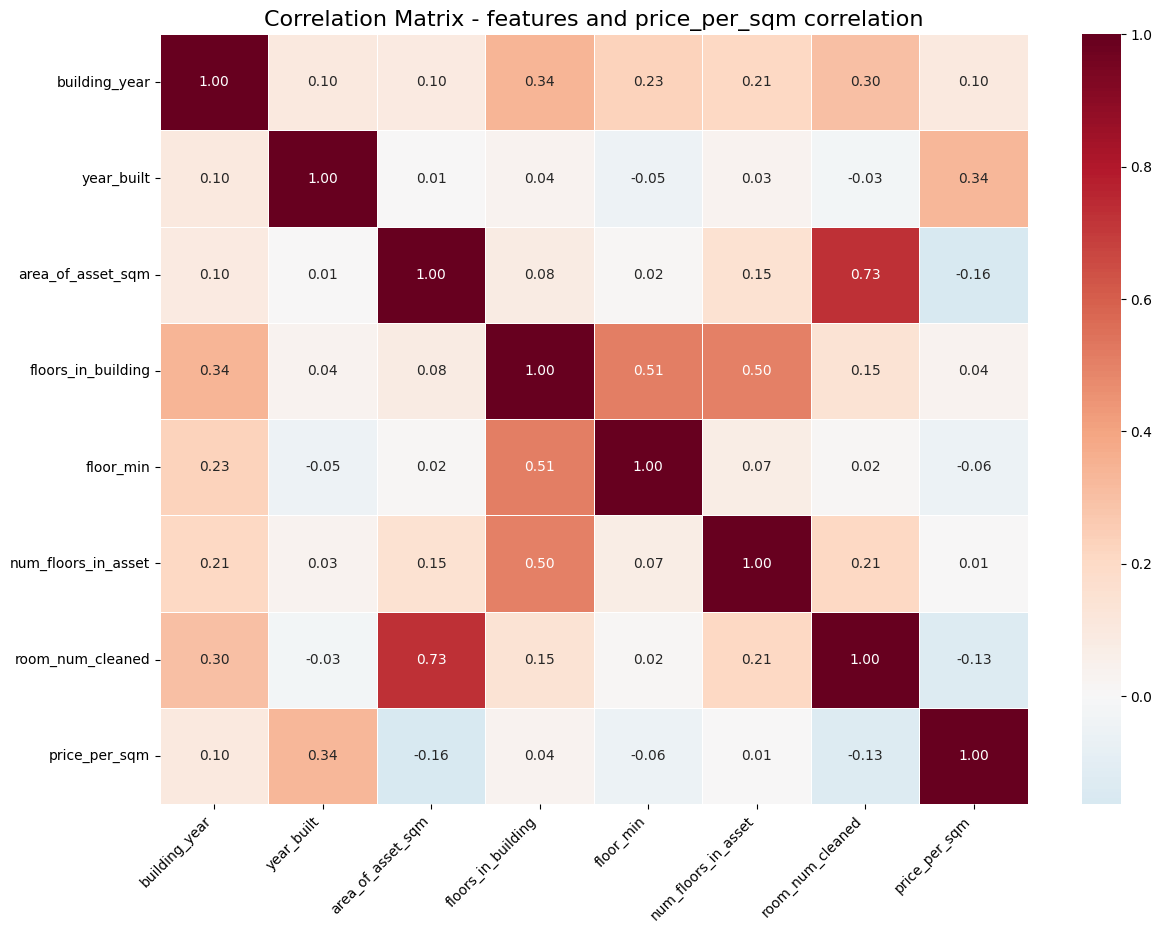

In [ ]:
# create heatmap
def plot_safe_correlation_matrix_price_sqm(df, numeric_columns, target_col='price_per_sqm'):
    df_corr = df.dropna(subset=[target_col]).copy()
    cols_to_remove = []
    clean_inputs = [col for col in numeric_columns if col not in cols_to_remove]
    actual_numeric_cols = df_corr[clean_inputs].select_dtypes(include=[np.number]).columns.tolist()

    if target_col not in actual_numeric_cols:
        actual_numeric_cols.append(target_col)

    valid_cols = []
    for col in actual_numeric_cols:
        if df_corr[col].nunique() > 1:
            valid_cols.append(col)
        else:
            print(f"Attention: '{col}' col removet from the matrice because it contains constant value only.")

    corr_matrix = df_corr[valid_cols].corr()
    fig, ax = plt.subplots(figsize=(14, 10))

    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='RdBu_r',
        center=0,
        fmt='.2f',
        linewidths=0.5,
        ax=ax,
        mask=corr_matrix.isnull()
    )

    title = f"Correlation Matrix - features and {target_col} correlation"
    ax.set_title(get_display(title), fontsize=16)

    plt.xticks(rotation=45, ha='right')

    plt.savefig('correlation_matrix_fixed.png', bbox_inches='tight')
    plt.show()

plot_safe_correlation_matrix_price_sqm(bs_data, num_cols_final)

#### **7.1.2. Total Deal Amount Correlation Heatmaps**

Same analysis, against `deal_amount` instead — comparing the two helps show whether a feature affects unit price or just scales with property size.

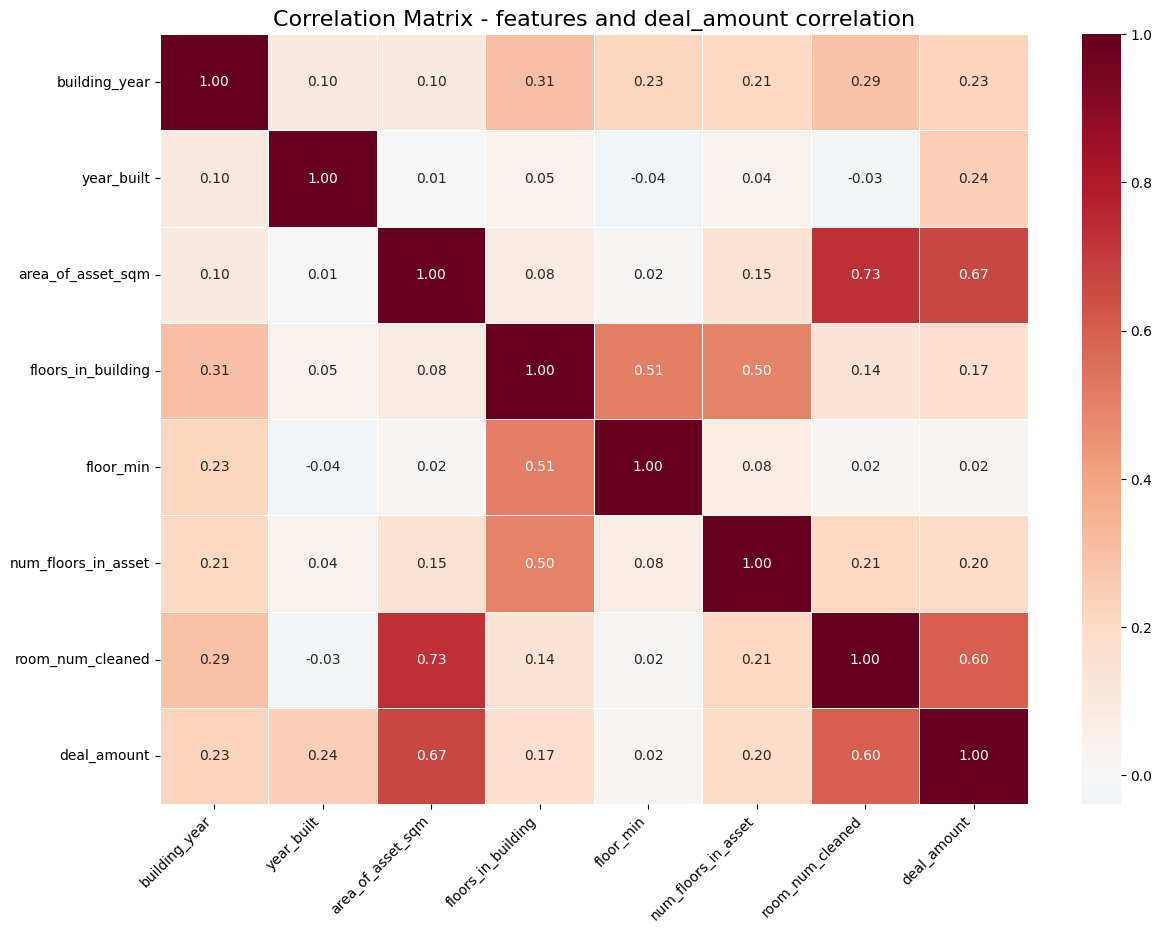

In [ ]:
#create heatmap
def plot_safe_correlation_matrix_deal_amount(df, numeric_columns, target_col='deal_amount'):
    df_corr = df.dropna(subset=[target_col]).copy()

    cols_to_remove = []

    clean_inputs = [col for col in numeric_columns if col not in cols_to_remove]
    actual_numeric_cols = df_corr[clean_inputs].select_dtypes(include=[np.number]).columns.tolist()

    if target_col not in actual_numeric_cols:
        actual_numeric_cols.append(target_col)

    valid_cols = []
    for col in actual_numeric_cols:
        if df_corr[col].nunique() > 1:
            valid_cols.append(col)
        else:
            print(f"שים לב: העמודה '{col}' הוסרה מהמטריצה כי היא מכילה ערך קבוע בלבד ולא ניתן לחשב לה קורלציה.")

    corr_matrix = df_corr[valid_cols].corr()
    fig, ax = plt.subplots(figsize=(14, 10))

    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='RdBu_r',
        center=0,
        fmt='.2f',
        linewidths=0.5,
        ax=ax,
        mask=corr_matrix.isnull()
    )

    title = f"Correlation Matrix - features and {target_col} correlation"
    ax.set_title(get_display(title), fontsize=16)

    plt.xticks(rotation=45, ha='right')

    plt.savefig('correlation_matrix_fixed.png', bbox_inches='tight')
    plt.show()

plot_safe_correlation_matrix_deal_amount(bs_data, num_cols_final)

### **7.2. Univariate Analysis**

Distribution of each variable on its own, without yet relating it to another variable.

#### **7.2.1 Histograms**

Density plots of numeric features, split by Innovation District status, to visually spot where distributions diverge.

======= VALIDATED_DATASET NUMERIC DISTRIBUTIONS vs DEAL_AMOUNT (Split by Innovation District) =======


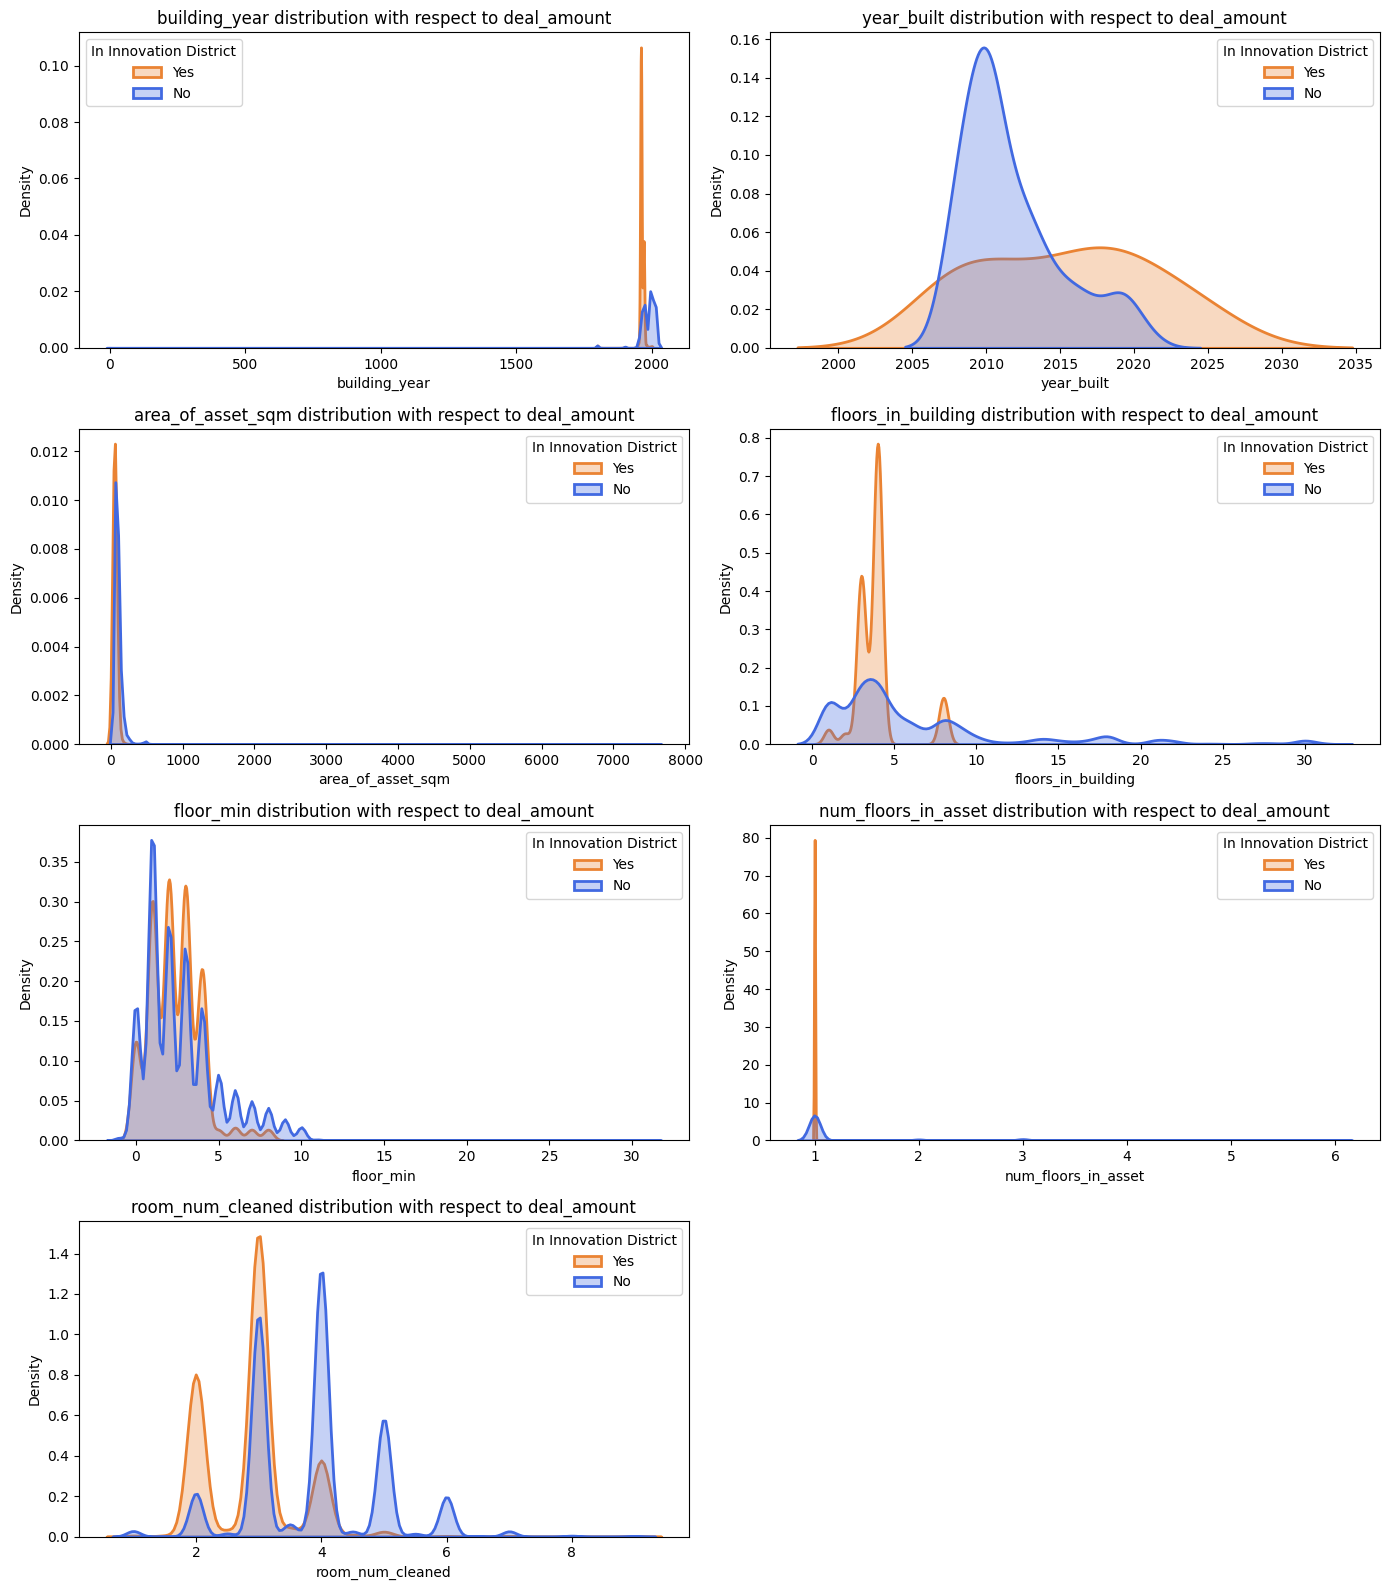

In [ ]:
# create histograms
def plot_validated_dealamount_distributions(df, cols_list, name="Data"):
    target_label = 'deal_amount'
    df_filtered = df.dropna(subset=[target_label]).copy()

    numeric_cols = [col for col in cols_list if col in df_filtered.columns and col != target_label]
    num_plots = len(numeric_cols)

    if num_plots == 0:
        print("No valid numeric cols to visualize.")
        return

    print(f"======= {name.upper()} NUMERIC DISTRIBUTIONS vs {target_label.upper()} (Split by Innovation District) =======")

    ncols = 2
    nrows = math.ceil(num_plots / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 4 * nrows))

    if num_plots == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, col in enumerate(numeric_cols):
        sns.kdeplot(data=df_filtered, x=col, hue='in_innovation_district',
                    ax=axes[i], fill=True, common_norm=False,
                    palette={0: 'royalblue', 1: '#EA8333'},
                    alpha=0.3, linewidth=2)

        title_text = f"{col} distribution with respect to {target_label}"
        axes[i].set_title(get_display(title_text), fontsize=12)
        axes[i].set_xlabel(get_display(col))
        axes[i].set_ylabel(get_display("Density"))

        axes[i].legend(title=get_display("In Innovation District"), labels=[get_display("Yes"), get_display("No")])

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_validated_dealamount_distributions(bs_data, num_cols_final, name="Validated_Dataset")

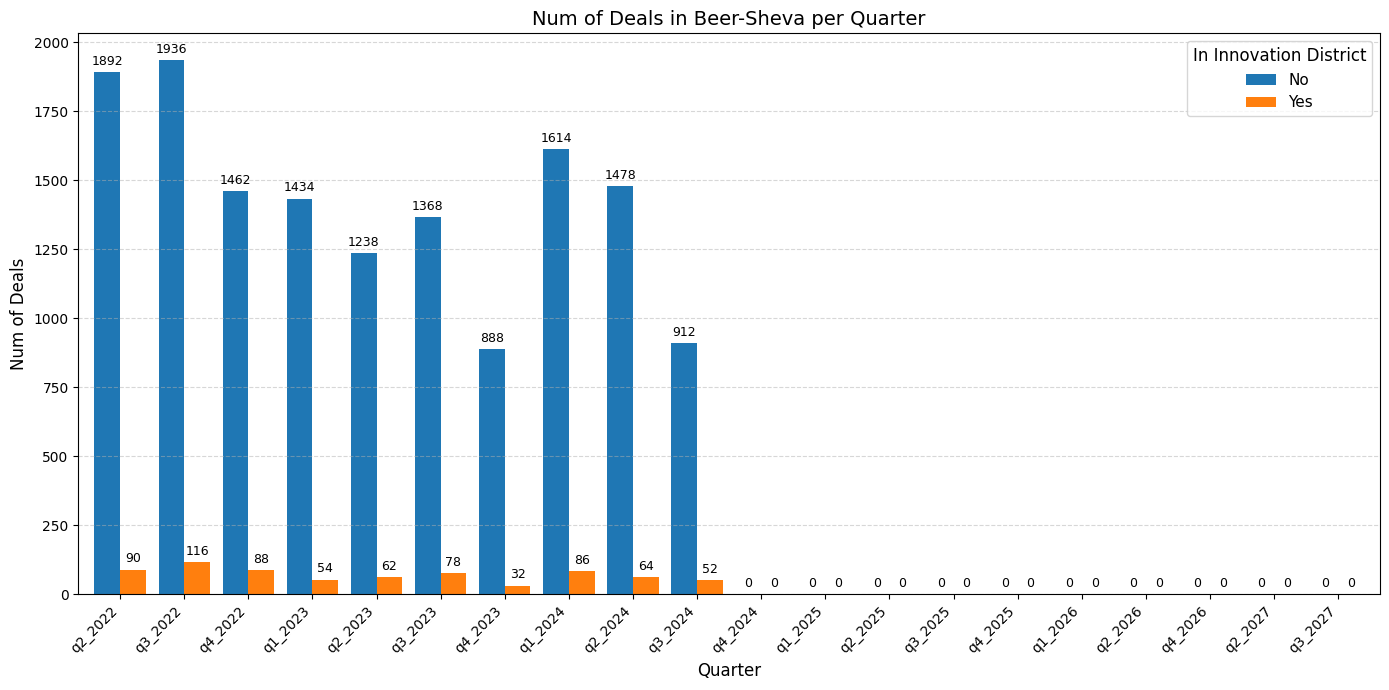

In [ ]:
def plot_comparative_quarterly_counts(df):
    pivot_data = df.groupby(['quarter_and_year', 'in_innovation_district']).size().unstack(fill_value=0)
    recent_data = pivot_data.tail(20)

    recent_data = recent_data.rename(columns={0: get_display("No"), 1: get_display("Yes")})
    ax = recent_data.plot(kind='bar', figsize=(14, 7), color=['#1f77b4', '#FF7F0E'], width=0.8)

    for container in ax.containers:
        ax.bar_label(container, padding=3, fontsize=9)

    plt.title(get_display("Num of Deals in Beer-Sheva per Quarter"), fontsize=14)
    plt.ylabel(get_display("Num of Deals"), fontsize=12)
    plt.xlabel(get_display("Quarter"), fontsize=12)

    plt.xticks(rotation=45, ha='right', fontsize=10)

    plt.legend(title=get_display("In Innovation District"), fontsize=11, title_fontsize=12)

    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

plot_comparative_quarterly_counts(bs_data)

======= ADVANCED LOWESS SMOOTHED TREND ANALYSIS (7 Features) =======


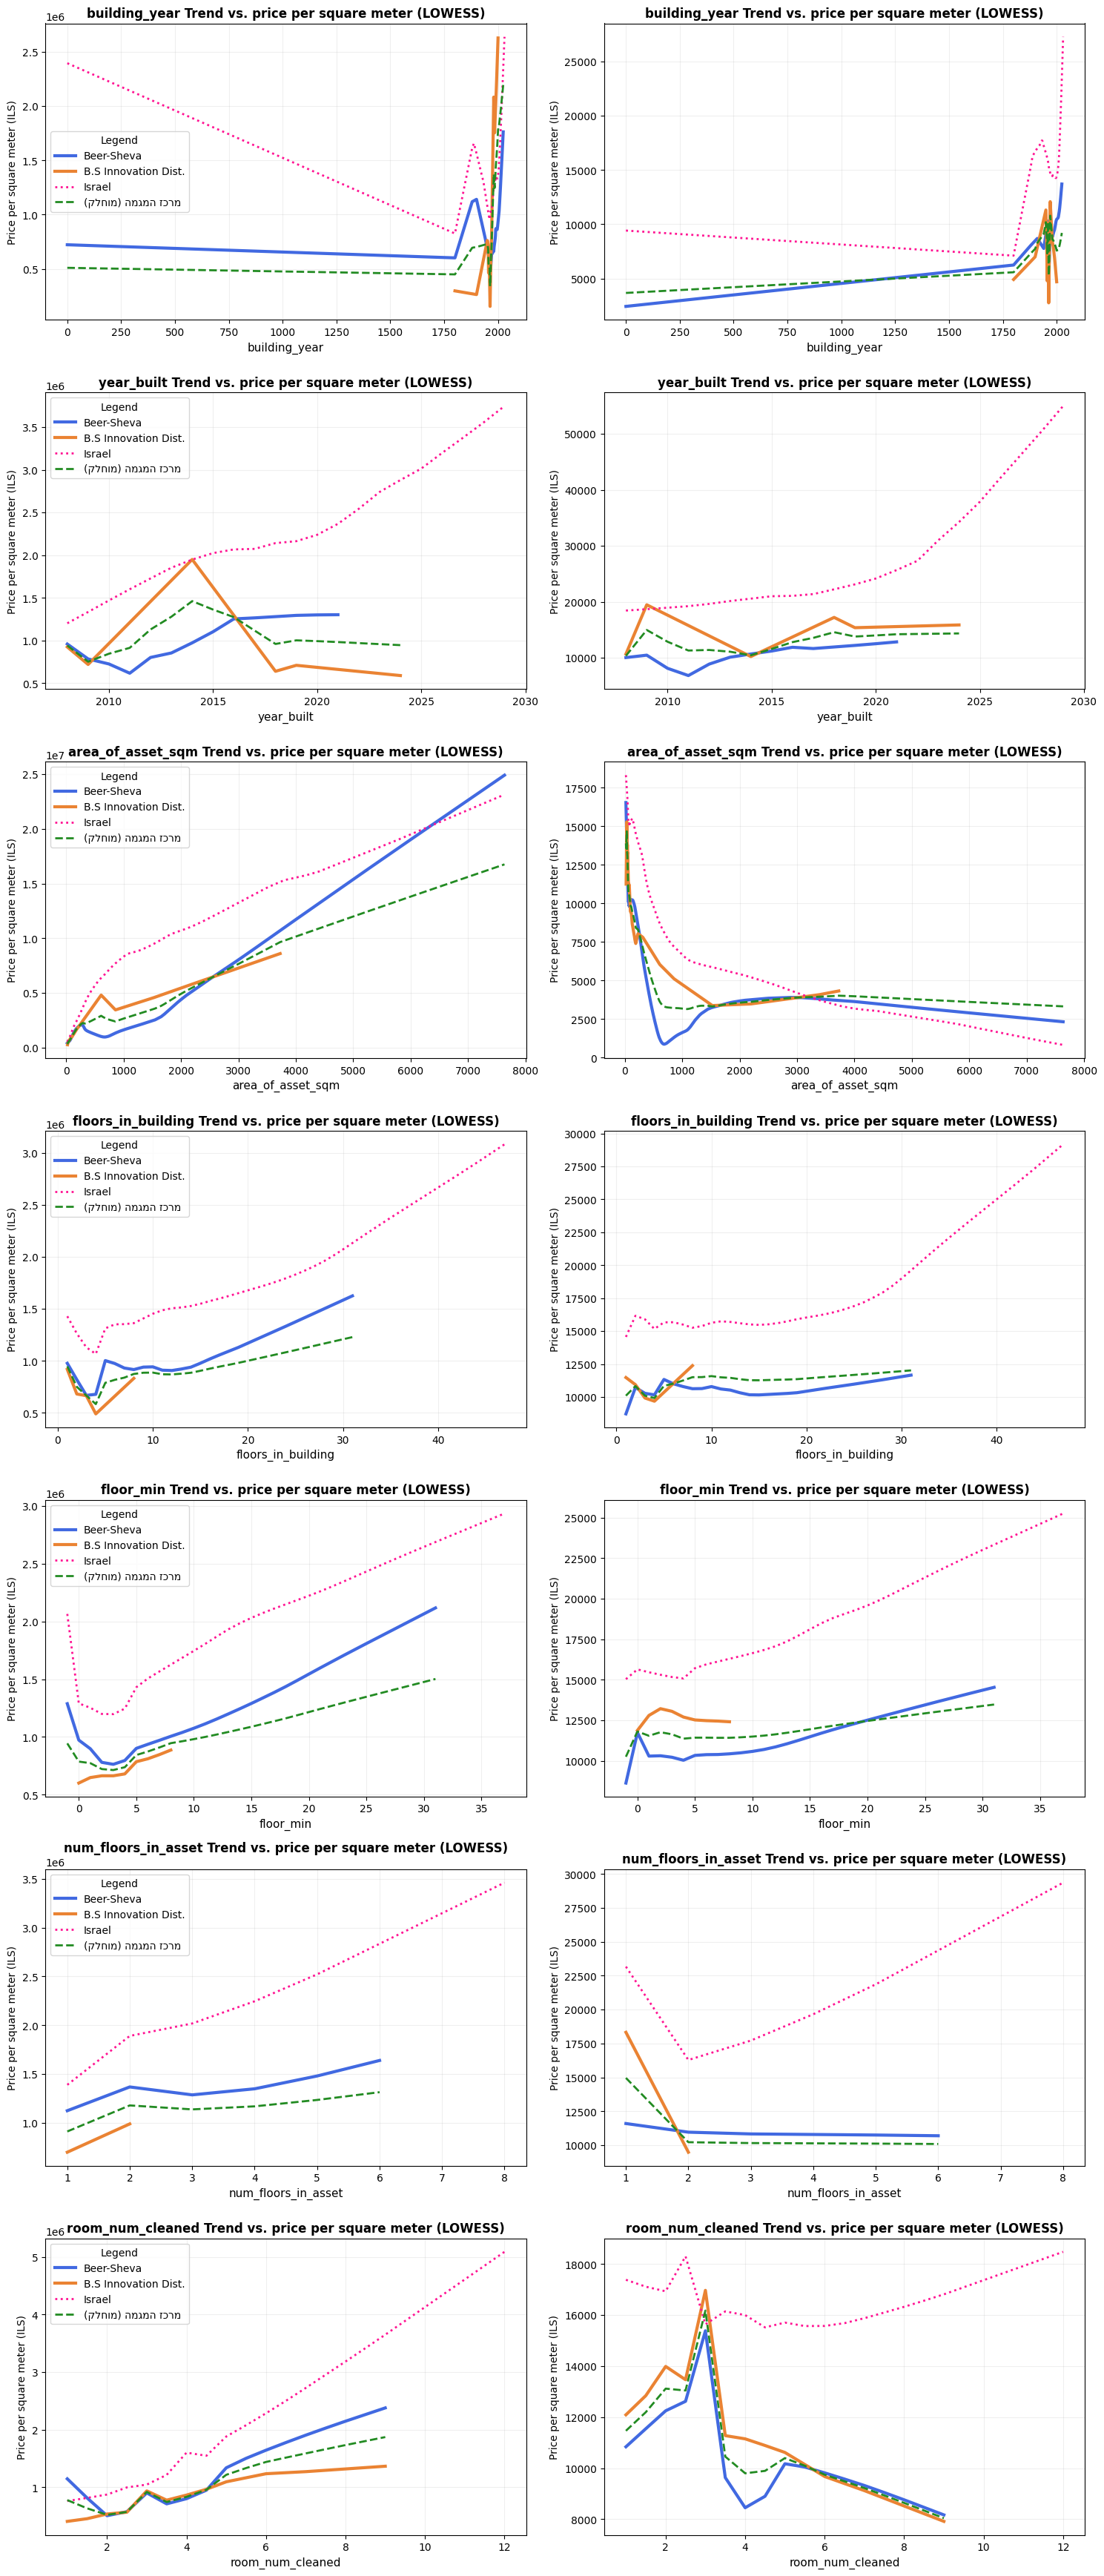

In [ ]:
def plot_all_numeric_lowess_trends(df_bs, df_country, cols_list, frac=0.4):
    """
    Draws a line-by-line trend graph with progressive LOWESS smoothing
    to eliminate jumps and noise in continuous variables (such as percentages and years).

    df_bs: The filtered data for Beersheba (for intra/extra-district division - blue/orange)
    df_country: All dataset_cleaned, unfiltered (for the pink line - "Israel")
    frac: The percentage of information used to smooth each point (default 0.4 - creates a smooth and clear line).
    """
    target_amount = 'deal_amount'
    target_price_sqm = 'price_per_sqm'

    # Clean up missing values ​​- for Beersheba and the whole country separately
    df_clean = df_bs.dropna(subset=[target_amount, target_price_sqm]).copy()
    df_country_clean = df_country.dropna(subset=[target_amount, target_price_sqm]).copy()

    # Filter the features (and remove labels from the list)
    features_to_plot = [col for col in cols_list if col in df_clean.columns
                        and col in df_country_clean.columns
                        and col not in [target_amount, target_price_sqm]]

    num_features = len(features_to_plot)

    if num_features == 0:
        print("No valid numeric features found to display.")
        return

    print(f"======= ADVANCED LOWESS SMOOTHED TREND ANALYSIS ({num_features} Features) =======")

    # Create the graph table (row per feature, 2 columns)
    fig, axes = plt.subplots(nrows=num_features, ncols=2, figsize=(15, 5 * num_features))
    if num_features == 1:
        axes = axes.reshape(1, 2)

    for idx, col in enumerate(features_to_plot):
        df_sorted = df_clean.sort_values(by=col)
        df_country_sorted = df_country_clean.sort_values(by=col)
        group_out = df_sorted[df_sorted['in_innovation_district'] == 0]
        group_in = df_sorted[df_sorted['in_innovation_district'] == 1]

        def get_lowess_xy(sub_df, x_col, y_col):
            if len(sub_df) < 5:
                return sub_df[x_col], sub_df[y_col]
            lowess_res = sm.nonparametric.lowess(sub_df[y_col], sub_df[x_col], frac=frac)
            return lowess_res[:, 0], lowess_res[:, 1]

        # Column 1 (right): Total deal amount
        ax1 = axes[idx, 0]

        x_out_low, y_out_low = get_lowess_xy(group_out, col, target_amount)
        x_in_low, y_in_low = get_lowess_xy(group_in, col, target_amount)
        x_isr_low, y_isr_low = get_lowess_xy(df_country_sorted, col, target_amount)

        ax1.plot(x_out_low, y_out_low, color='royalblue', linewidth=3, label=get_display("Beer-Sheva"))
        ax1.plot(x_in_low, y_in_low, color='#EA8333', linewidth=3, label=get_display("B.S Innovation Dist."))
        ax1.plot(x_isr_low, y_isr_low, color='deeppink', linewidth=2, linestyle=':', label=get_display("Israel"))

        all_x = np.unique(np.concatenate([x_out_low, x_in_low]))
        y_out_interp = np.interp(all_x, x_out_low, y_out_low)
        y_in_interp = np.interp(all_x, x_in_low, y_in_low)
        y_macro_fair = (y_out_interp + y_in_interp) / 2

        ax1.plot(all_x, y_macro_fair, color='forestgreen', linewidth=2, linestyle='--', label=get_display("מרכז המגמה (מוחלק)"))
        ax1.set_title(get_display(f"{col} Trend vs. price per square meter (LOWESS)"), fontsize=12, fontweight='bold')
        ax1.set_ylabel(get_display("Price per square meter (ILS)"))
        ax1.set_xlabel(get_display(col), fontsize=11)
        ax1.grid(True, alpha=0.2)
        ax1.legend(title=get_display("Legend"))

        # Column 2 (left): Price per SQM
        ax2 = axes[idx, 1]

        x_out_low_p, y_out_low_p = get_lowess_xy(group_out, col, target_price_sqm)
        x_in_low_p, y_in_low_p = get_lowess_xy(group_in, col, target_price_sqm)
        x_isr_low_p, y_isr_low_p = get_lowess_xy(df_country_sorted, col, target_price_sqm)

        ax2.plot(x_out_low_p, y_out_low_p, color='royalblue', linewidth=3)
        ax2.plot(x_in_low_p, y_in_low_p, color='#EA8333', linewidth=3)
        ax2.plot(x_isr_low_p, y_isr_low_p, color='deeppink', linewidth=2, linestyle=':')

        all_x_p = np.unique(np.concatenate([x_out_low_p, x_in_low_p]))
        y_out_interp_p = np.interp(all_x_p, x_out_low_p, y_out_low_p)
        y_in_interp_p = np.interp(all_x_p, x_in_low_p, y_in_low_p)
        y_macro_fair_p = (y_out_interp_p + y_in_interp_p) / 2

        ax2.plot(all_x_p, y_macro_fair_p, color='forestgreen', linewidth=2, linestyle='--')

        ax2.set_title(get_display(f"{col} Trend vs. price per square meter (LOWESS)"), fontsize=12, fontweight='bold')
        ax2.set_ylabel(get_display("Price per square meter (ILS)"))
        ax2.set_xlabel(get_display(col), fontsize=11)
        ax2.grid(True, alpha=0.2)

    plt.tight_layout()
    plt.show()

sample_60k = dataset_cleaned.sample(n=min(60000, len(dataset_cleaned)), random_state=1)
plot_all_numeric_lowess_trends(bs_data, sample_60k, num_cols_final, frac=0.3)


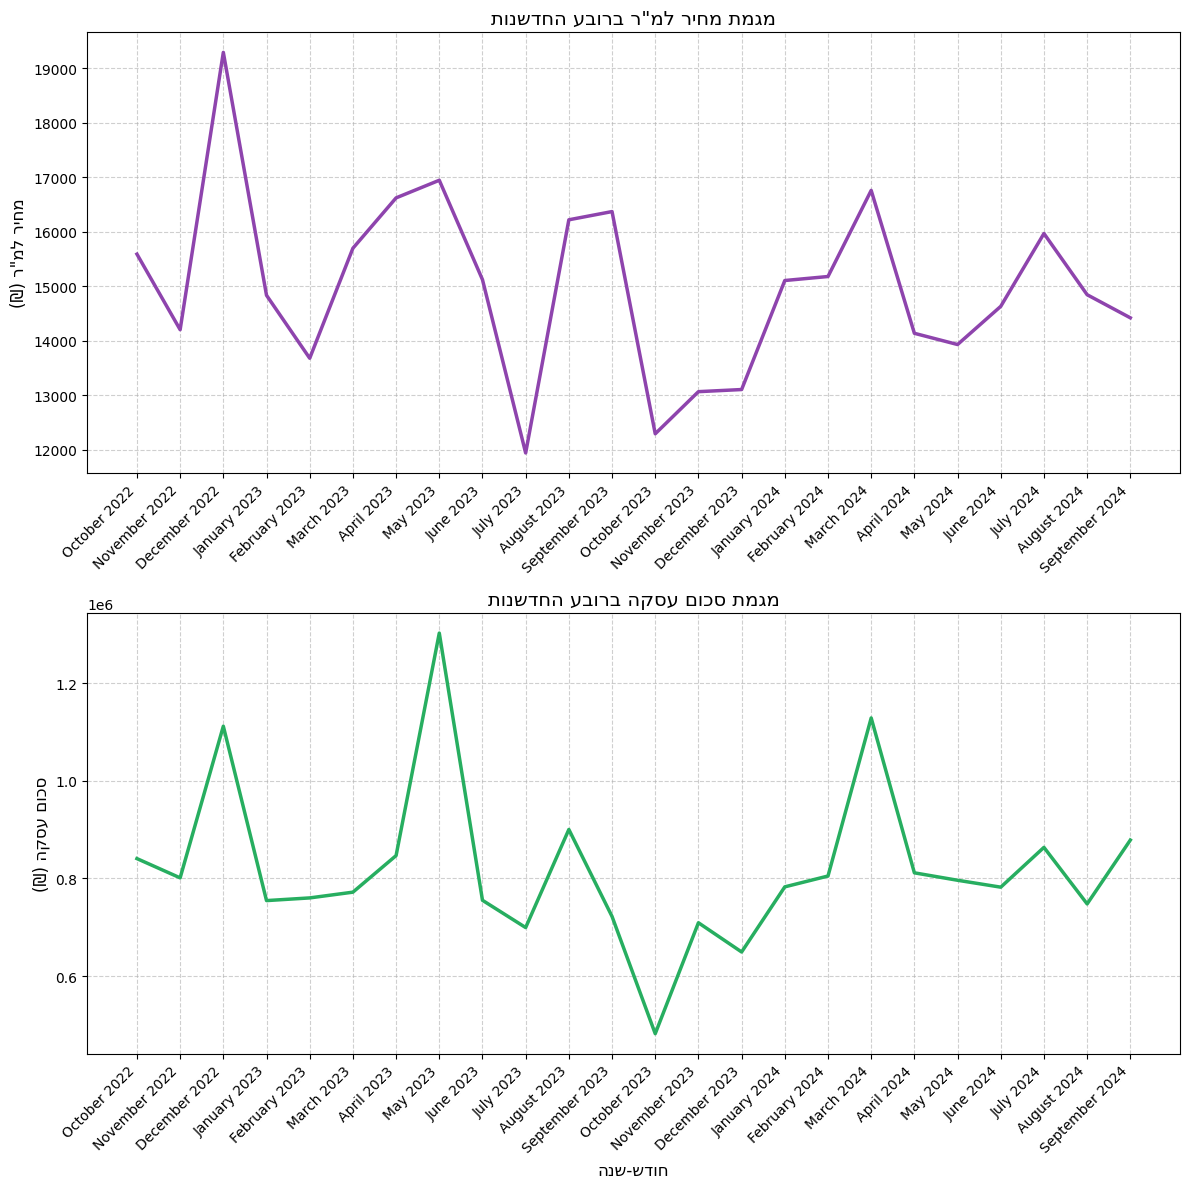

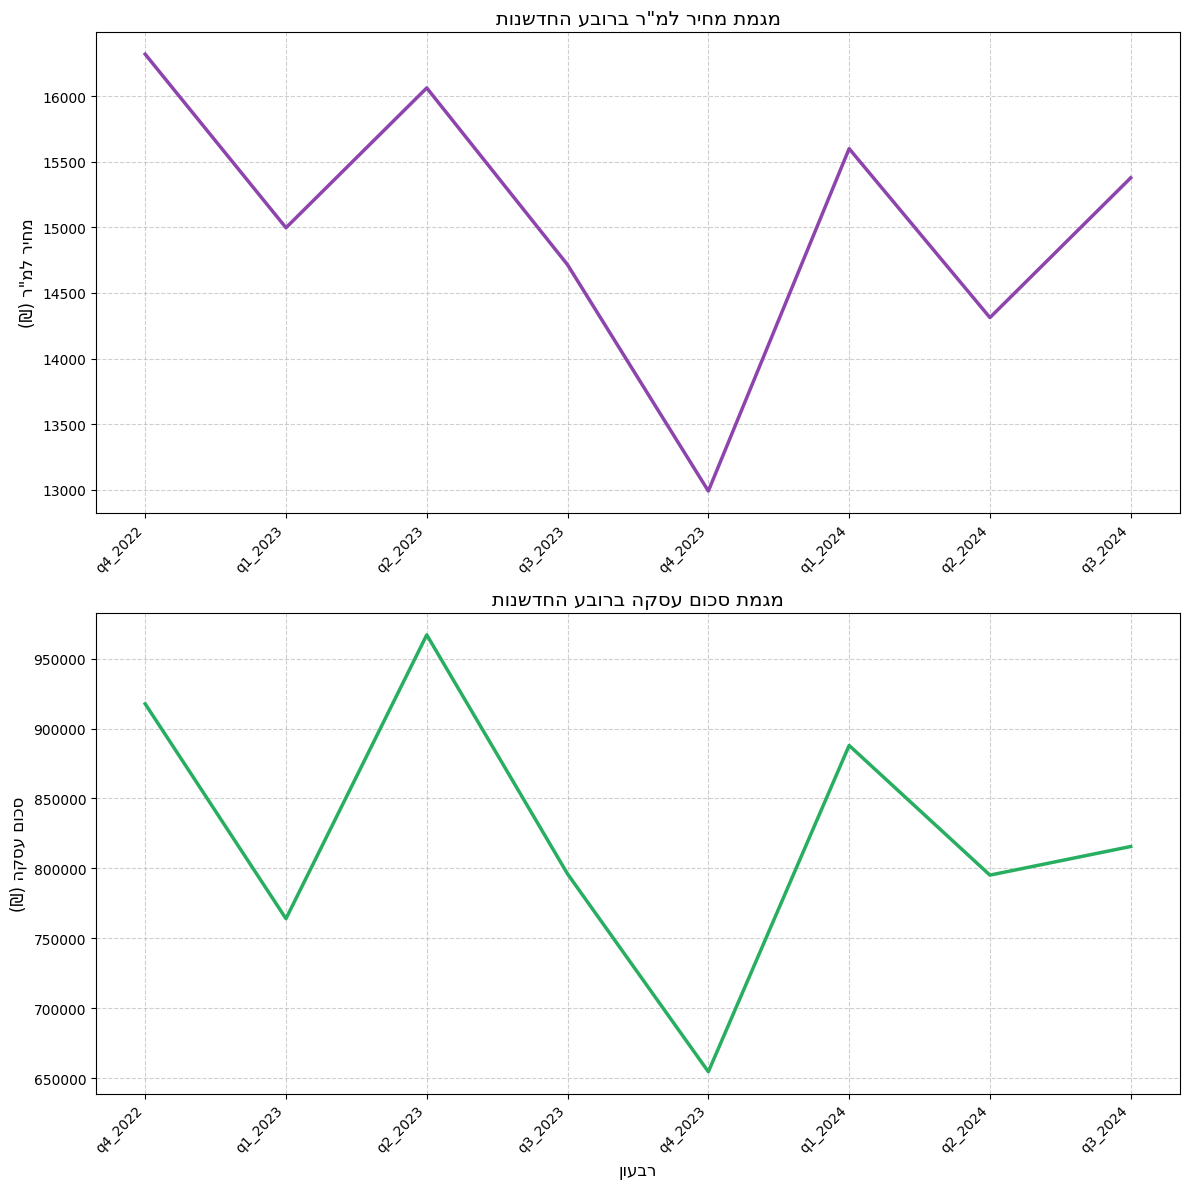

In [ ]:
def plot_two_separate_trends_fixed(df, period_col='month_and_year', periods_back=24):
    """
    period_col: 'month_and_year' or 'quarter_and_year' (your existing columns)
    periods_back: how many periods (months or quarters) back to show
    """
    # 1. סינון לרובע החדשנות בלבד
    innovation_df = df[df['in_innovation_district'] == 1].copy()
    innovation_df['deal_date_time'] = pd.to_datetime(innovation_df['deal_date_time'], errors='coerce')

    # 2. סינון שורות בלי תקופה תקינה
    innovation_df = innovation_df.dropna(subset=[period_col, 'deal_date_time'])

    # 3. סדר כרונולוגי של התקופות בפועל (לפי תאריך עסקה, לא לפי הסדר האלפביתי)
    ordered_periods = (
        innovation_df.sort_values('deal_date_time')[period_col]
        .drop_duplicates()
        .tolist()
    )

    # 4. לקיחת ה-N תקופות האחרונות הקיימות בפועל
    last_periods = ordered_periods[-periods_back:]
    recent_data = innovation_df[innovation_df[period_col].isin(last_periods)].copy()

    # 5. אגרגציה - שומר על הסדר הכרונולוגי
    period_stats = recent_data.groupby(period_col, observed=True)[['price_per_sqm', 'deal_amount']].mean()
    period_stats = period_stats.reindex(last_periods).reset_index()
    period_stats['date_str'] = period_stats[period_col].astype(str)

    # 6. בניית 2 גרפים (ללא sharex כדי לקבל שליטה מלאה)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12))

    # צבעים נבחרים
    color_sqm = '#8E44AD'  # סגול
    color_amount = '#27AE60' # ירוק זית

    # מיקום התוויות (עבור ציר ה-X)
    x_indices = range(len(period_stats))
    labels = period_stats['date_str']

    period_label = get_display('רבעון') if period_col == 'quarter_and_year' else get_display('חודש-שנה')

    # גרף ראשון: מחיר למ"ר
    ax1.plot(x_indices, period_stats['price_per_sqm'],
             color=color_sqm, marker=None, linewidth=2.5)
    ax1.set_ylabel(get_display('מחיר למ"ר (₪)'), fontsize=12)
    ax1.set_title(get_display('מגמת מחיר למ"ר ברובע החדשנות'), fontsize=14)
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.set_xticks(x_indices)
    ax1.set_xticklabels(labels, rotation=45, ha='right')

    # גרף שני: סכום עסקה
    ax2.plot(x_indices, period_stats['deal_amount'],
             color=color_amount, marker=None, linewidth=2.5)
    ax2.set_ylabel(get_display('סכום עסקה (₪)'), fontsize=12)
    ax2.set_title(get_display('מגמת סכום עסקה ברובע החדשנות'), fontsize=14)
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.set_xticks(x_indices)
    ax2.set_xticklabels(labels, rotation=45, ha='right')
    ax2.set_xlabel(period_label, fontsize=12)

    plt.tight_layout()
    plt.show()

# הרצה - חודשי (כמו קודם)
plot_two_separate_trends_fixed(bs_data, period_col='month_and_year', periods_back=24)

# הרצה - רבעוני, עם העמודה שכבר יש לך
plot_two_separate_trends_fixed(bs_data, period_col='quarter_and_year', periods_back=8)

### **Countplots - Categoric Cols Distribution**

Bar counts of categorical features, split by Innovation District status.

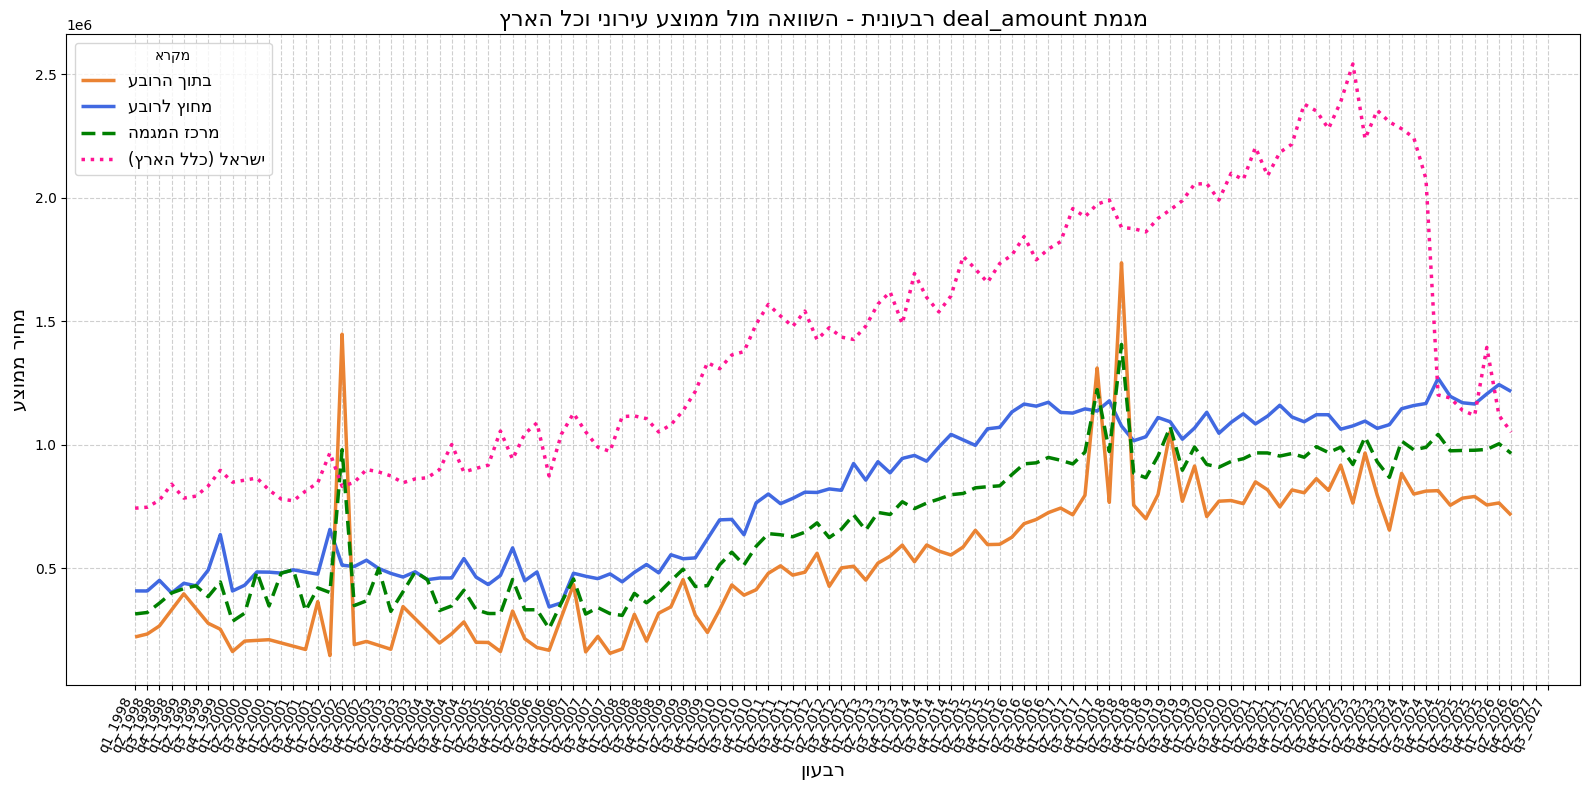

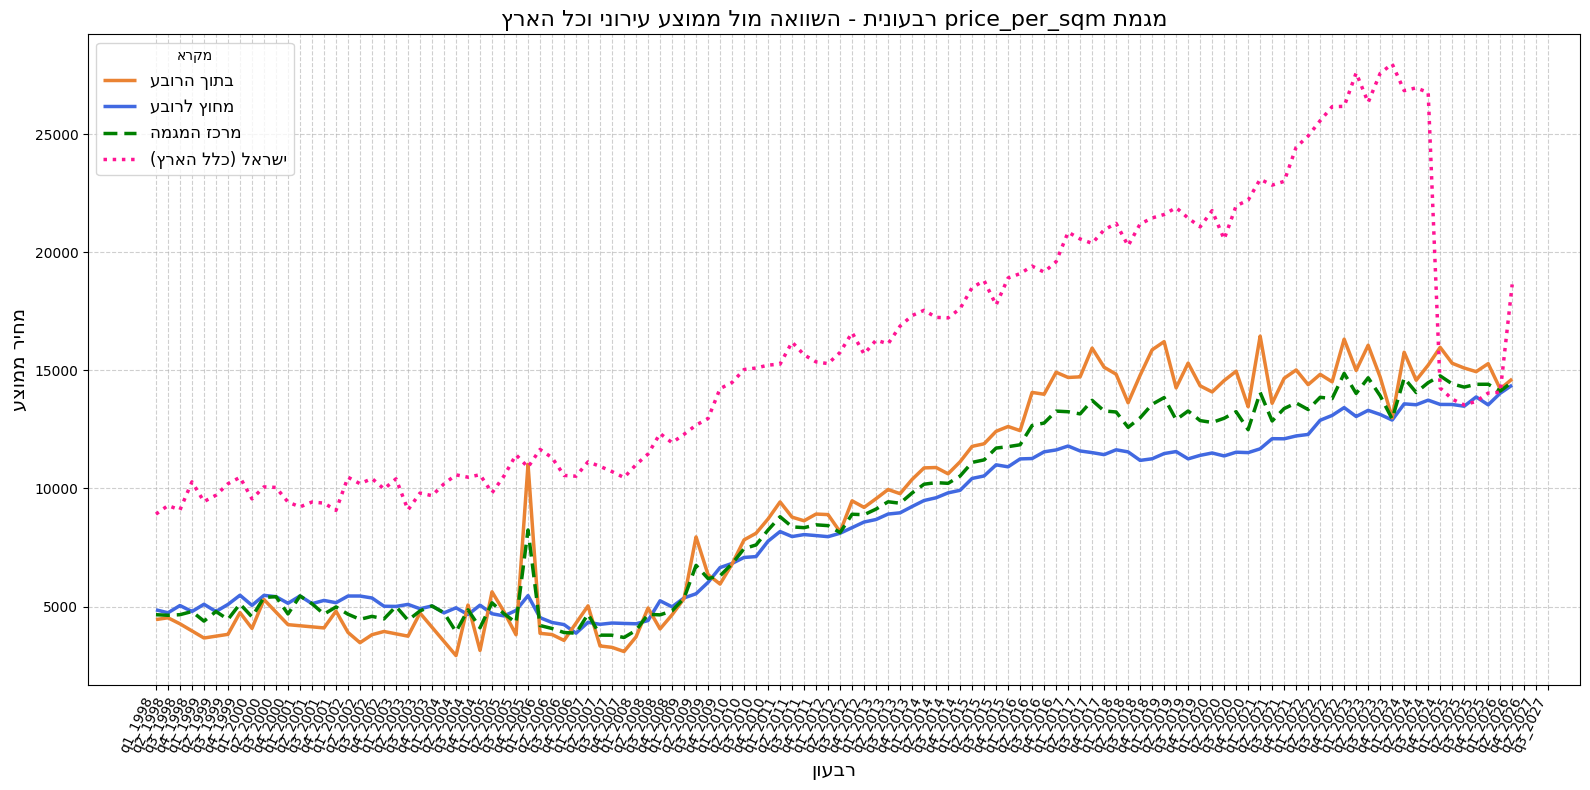

In [ ]:
def plot_professional_quarterly_trends_final(df, target_label='deal_amount', df_national=None):
    """
    df_national: the 60K national sample (or any national df) used for the pink dotted line.
                 If None, the pink line is skipped.
    """
    # 1. סינון שורות ריקות בערך המטרה ובזמן
    df_clean = df.dropna(subset=['quarter_and_year', target_label]).copy()

    # 2. חישוב ממוצע בתוך כל קבוצה (מחוץ/בתוך הרובע)
    group_stats = df_clean.groupby(['quarter_and_year', 'in_innovation_district'], observed=False)[target_label].mean().reset_index()

    # 3. חישוב "ממוצע של ממוצעים" (הקו הירוק)
    mean_of_means = group_stats.groupby('quarter_and_year', observed=False)[target_label].mean().reset_index()
    mean_of_means['in_innovation_district'] = 2  # מזהה מיוחד ל"מרכז המגמה"

    # 4. הכנת טבלת הנתונים לגרף
    plot_data = pd.concat([group_stats, mean_of_means], ignore_index=True)

    # מיפוי שמות בעברית
    district_map = {0: 'מחוץ לרובע', 1: 'בתוך הרובע', 2: 'מרכז המגמה'}
    plot_data['district_name'] = plot_data['in_innovation_district'].map(district_map)

    # הגדרת צבעים מדויקת
    palette = {'מחוץ לרובע': 'royalblue', 'בתוך הרובע': '#EA8333', 'מרכז המגמה': 'green'}

    # הגדרת קווים מקווקווים - רק "מרכז המגמה" יהיה מקווקו
    dashes_map = {'מחוץ לרובע': (1, 0), 'בתוך הרובע': (1, 0), 'מרכז המגמה': (4, 2)}

    plt.figure(figsize=(16, 8))

    # 5. ציור הגרף
    ax = sns.lineplot(
        data=plot_data,
        x='quarter_and_year',
        y=target_label,
        hue='district_name',
        style='district_name',
        markers=False,
        dashes=dashes_map,
        palette=palette,
        linewidth=2.5
    )

    # 5.5. הוספת קו ורוד מנוקד - ממוצע ארצי (מהדגימה של 60K)
    categories = list(plot_data['quarter_and_year'].cat.categories) if hasattr(plot_data['quarter_and_year'], 'cat') else sorted(plot_data['quarter_and_year'].unique())

    if df_national is not None:
        national_clean = df_national.dropna(subset=['quarter_and_year', target_label]).copy()
        national_stats = national_clean.groupby('quarter_and_year', observed=False)[target_label].mean()

        # שמירה על אותו סדר קטגוריות כמו בגרף הראשי, רק לרבעונים שקיימים שם
        national_stats = national_stats.reindex(categories)

        x_positions = range(len(categories))
        ax.plot(
            x_positions,
            national_stats.values,
            color='deeppink',
            linestyle=':',
            linewidth=2.5,
            label=get_display('ישראל (כלל הארץ)')
        )

    # 6. סידור מקרא מדויק לפי הסדר שביקשת
    handles, labels = ax.get_legend_handles_labels()
    ordered_labels_map = {'בתוך הרובע': 0, 'מחוץ לרובע': 1, 'מרכז המגמה': 2, get_display('ישראל (כלל הארץ)'): 3}
    ordered_pairs = sorted(zip(handles, labels), key=lambda x: ordered_labels_map.get(x[1], 99))
    ordered_handles, ordered_labels = zip(*ordered_pairs)

    # תרגום תוויות (אלו שעדיין בעברית "רגילה" ולא עברו get_display)
    final_labels = [l if l == get_display('ישראל (כלל הארץ)') else get_display(l) for l in ordered_labels]

    ax.legend(
        handles=ordered_handles,
        labels=final_labels,
        title=get_display("מקרא"),
        loc='best',
        fontsize=12
    )

    # 7. עיצוב צירים
    plt.title(get_display(f"מגמת {target_label} רבעונית - השוואה מול ממוצע עירוני וכל הארץ"), fontsize=16)
    plt.xlabel(get_display("רבעון"), fontsize=14)
    plt.ylabel(get_display("מחיר ממוצע"), fontsize=14)

    plt.xticks(
        ticks=range(len(categories)),
        labels=[get_display(str(c)) for c in categories],
        rotation=65, ha='right', fontsize=10
    )

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# הרצה - עם הקו הוורוד הארצי מתוך הדגימה של 60K
plot_professional_quarterly_trends_final(dataset_cleaned, target_label='deal_amount', df_national=sample_60k)
plot_professional_quarterly_trends_final(dataset_cleaned, target_label='price_per_sqm', df_national=sample_60k)

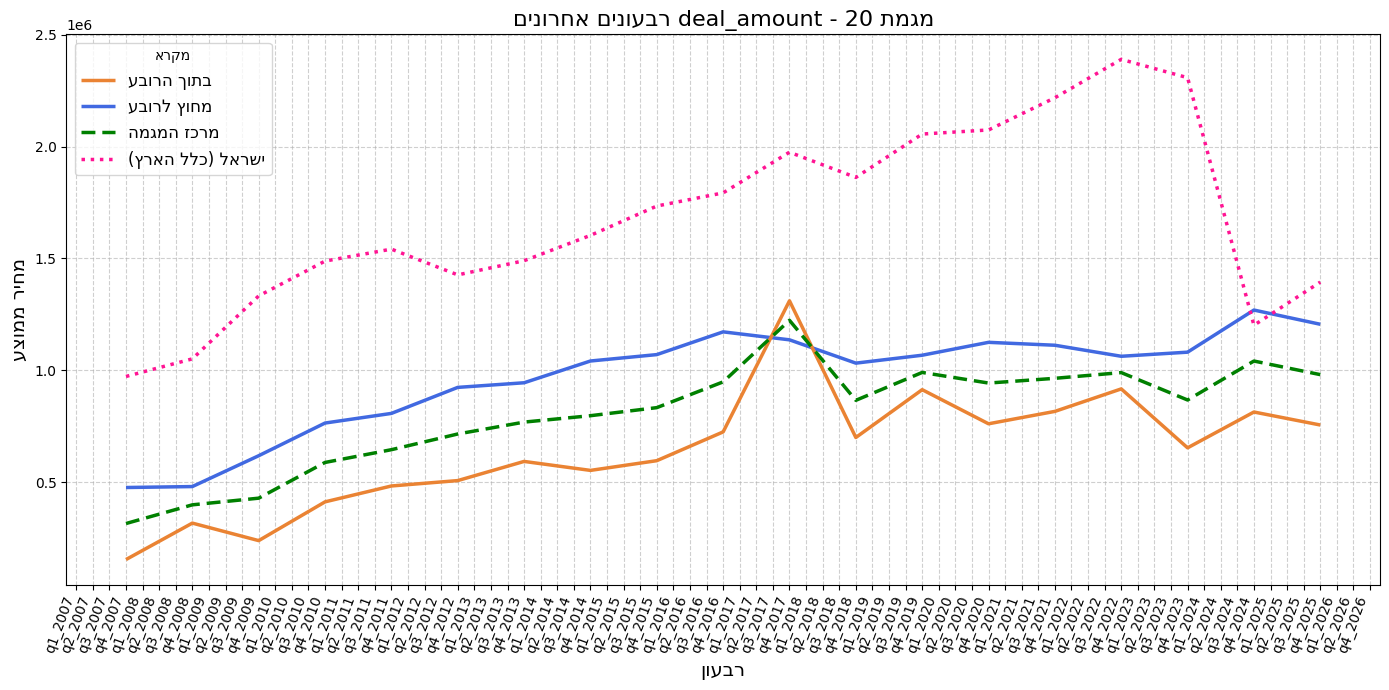

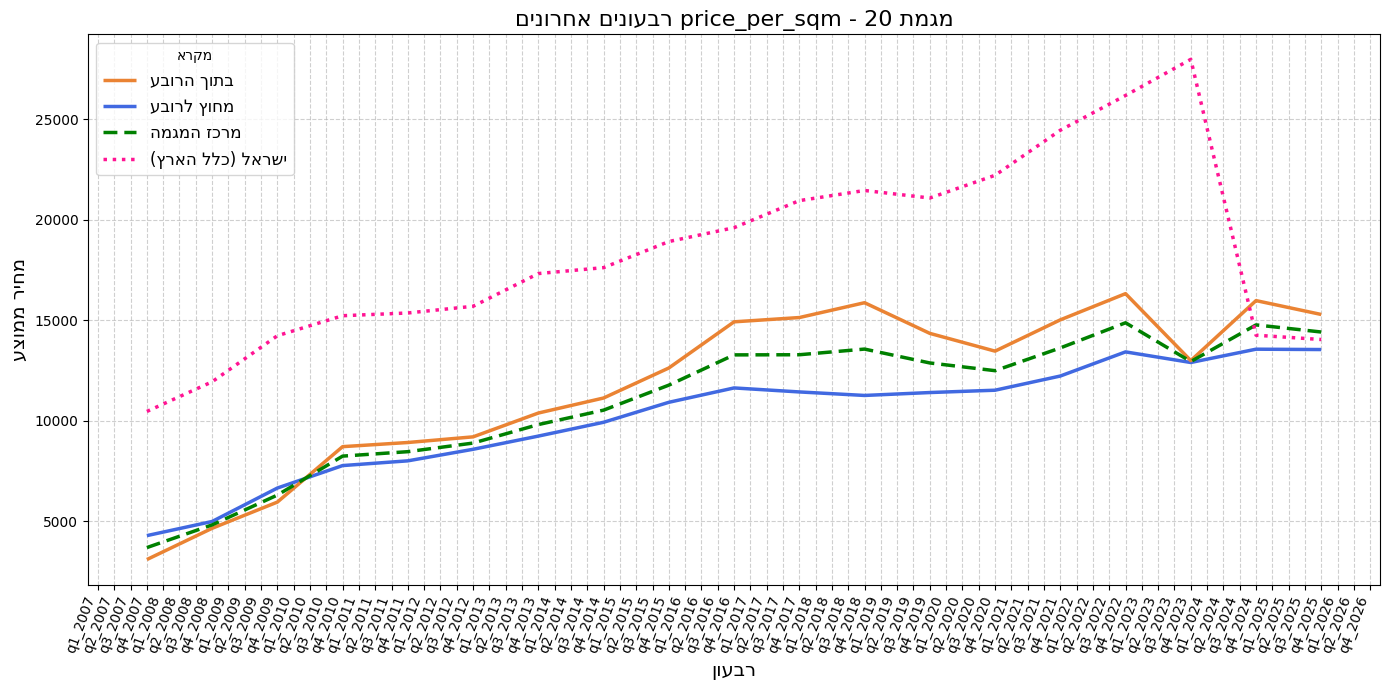

In [ ]:
def plot_professional_quarterly_trends_final_5_years(df, target_label='deal_amount', df_national=None):
    """
    df_national: the 60K national sample (or any national df) used for the pink dotted line.
                 If None, the pink line is skipped.
    """
    # 1. סינון שורות ריקות בערך המטרה ובזמן
    df_clean = df.dropna(subset=['quarter_and_year', target_label]).copy()

    # 1.5 סינון ל-20 הרבעונים האחרונים בלבד
    # אנחנו מניחים שהעמודה ממוינת כרונולוגית (Categorical או סודרת)
    last_20_quarters = sorted(df_clean['quarter_and_year'].unique())[-20:]
    df_clean = df_clean[df_clean['quarter_and_year'].isin(last_20_quarters)]

    # 2. חישוב ממוצע בתוך כל קבוצה (מחוץ/בתוך הרובע)
    group_stats = df_clean.groupby(['quarter_and_year', 'in_innovation_district'], observed=False)[target_label].mean().reset_index()

    # 3. חישוב "ממוצע של ממוצעים" (הקו הירוק)
    mean_of_means = group_stats.groupby('quarter_and_year', observed=False)[target_label].mean().reset_index()
    mean_of_means['in_innovation_district'] = 2 # מזהה מיוחד ל"מרכז המגמה"

    # 4. הכנת טבלת הנתונים לגרף
    plot_data = pd.concat([group_stats, mean_of_means], ignore_index=True)

    # מיפוי שמות בעברית
    district_map = {0: 'מחוץ לרובע', 1: 'בתוך הרובע', 2: 'מרכז המגמה'}
    plot_data['district_name'] = plot_data['in_innovation_district'].map(district_map)

    # הגדרת צבעים מדויקת
    palette = {'מחוץ לרובע': 'royalblue', 'בתוך הרובע': '#EA8333', 'מרכז המגמה': 'green'}

    # הגדרת קווים מקווקווים - רק "מרכז המגמה" יהיה מקווקו
    dashes_map = {'מחוץ לרובע': (1, 0), 'בתוך הרובע': (1, 0), 'מרכז המגמה': (4, 2)}

    plt.figure(figsize=(14, 7))

    # 5. ציור הגרף
    ax = sns.lineplot(
        data=plot_data,
        x='quarter_and_year',
        y=target_label,
        hue='district_name',
        style='district_name',
        markers=False,
        dashes=dashes_map,
        palette=palette,
        linewidth=2.5
    )

    # 5.5. הוספת קו ורוד מנוקד - ממוצע ארצי (מהדגימה של 60K), רק על אותם 20 רבעונים
    if df_national is not None:
        # שמירה על אותו סדר קטגוריות כמו שמשתמש בו sns.lineplot בגרף הראשי
        if hasattr(plot_data['quarter_and_year'], 'cat'):
            categories = [c for c in plot_data['quarter_and_year'].cat.categories if c in last_20_quarters]
        else:
            categories = last_20_quarters

        national_clean = df_national.dropna(subset=['quarter_and_year', target_label]).copy()
        national_clean = national_clean[national_clean['quarter_and_year'].isin(last_20_quarters)]
        national_stats = national_clean.groupby('quarter_and_year', observed=False)[target_label].mean()
        national_stats = national_stats.reindex(categories)

        x_positions = range(len(categories))
        ax.plot(
            categories,
            national_stats.values,
            color='deeppink',
            linestyle=':',
            linewidth=2.5,
            label=get_display('ישראל (כלל הארץ)')
        )

    # 6. סידור מקרא מדויק
    handles, labels = ax.get_legend_handles_labels()
    ordered_labels_map = {'בתוך הרובע': 0, 'מחוץ לרובע': 1, 'מרכז המגמה': 2, get_display('ישראל (כלל הארץ)'): 3}

    # סידור ה-handles לפי הסדר הרצוי
    ordered_pairs = sorted(zip(handles, labels), key=lambda x: ordered_labels_map.get(x[1], 99))
    ordered_handles, ordered_labels = zip(*ordered_pairs)

    # תרגום תוויות (אלו שעדיין בעברית "רגילה" ולא עברו get_display)
    final_labels = [l if l == get_display('ישראל (כלל הארץ)') else get_display(l) for l in ordered_labels]

    ax.legend(
        handles=ordered_handles,
        labels=final_labels,
        title=get_display("מקרא"),
        loc='best',
        fontsize=12
    )

    # 7. עיצוב צירים
    plt.title(get_display(f"מגמת {target_label} - 20 רבעונים אחרונים"), fontsize=16)
    plt.xlabel(get_display("רבעון"), fontsize=14)
    plt.ylabel(get_display("מחיר ממוצע"), fontsize=14)

    # סיבוב תוויות ציר ה-X
    plt.xticks(rotation=70, ha='right', fontsize=10)

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# הרצה
plot_professional_quarterly_trends_final_5_years(dataset_cleaned, target_label='deal_amount', df_national=sample_60k)
plot_professional_quarterly_trends_final_5_years(dataset_cleaned, target_label='price_per_sqm', df_national=sample_60k)

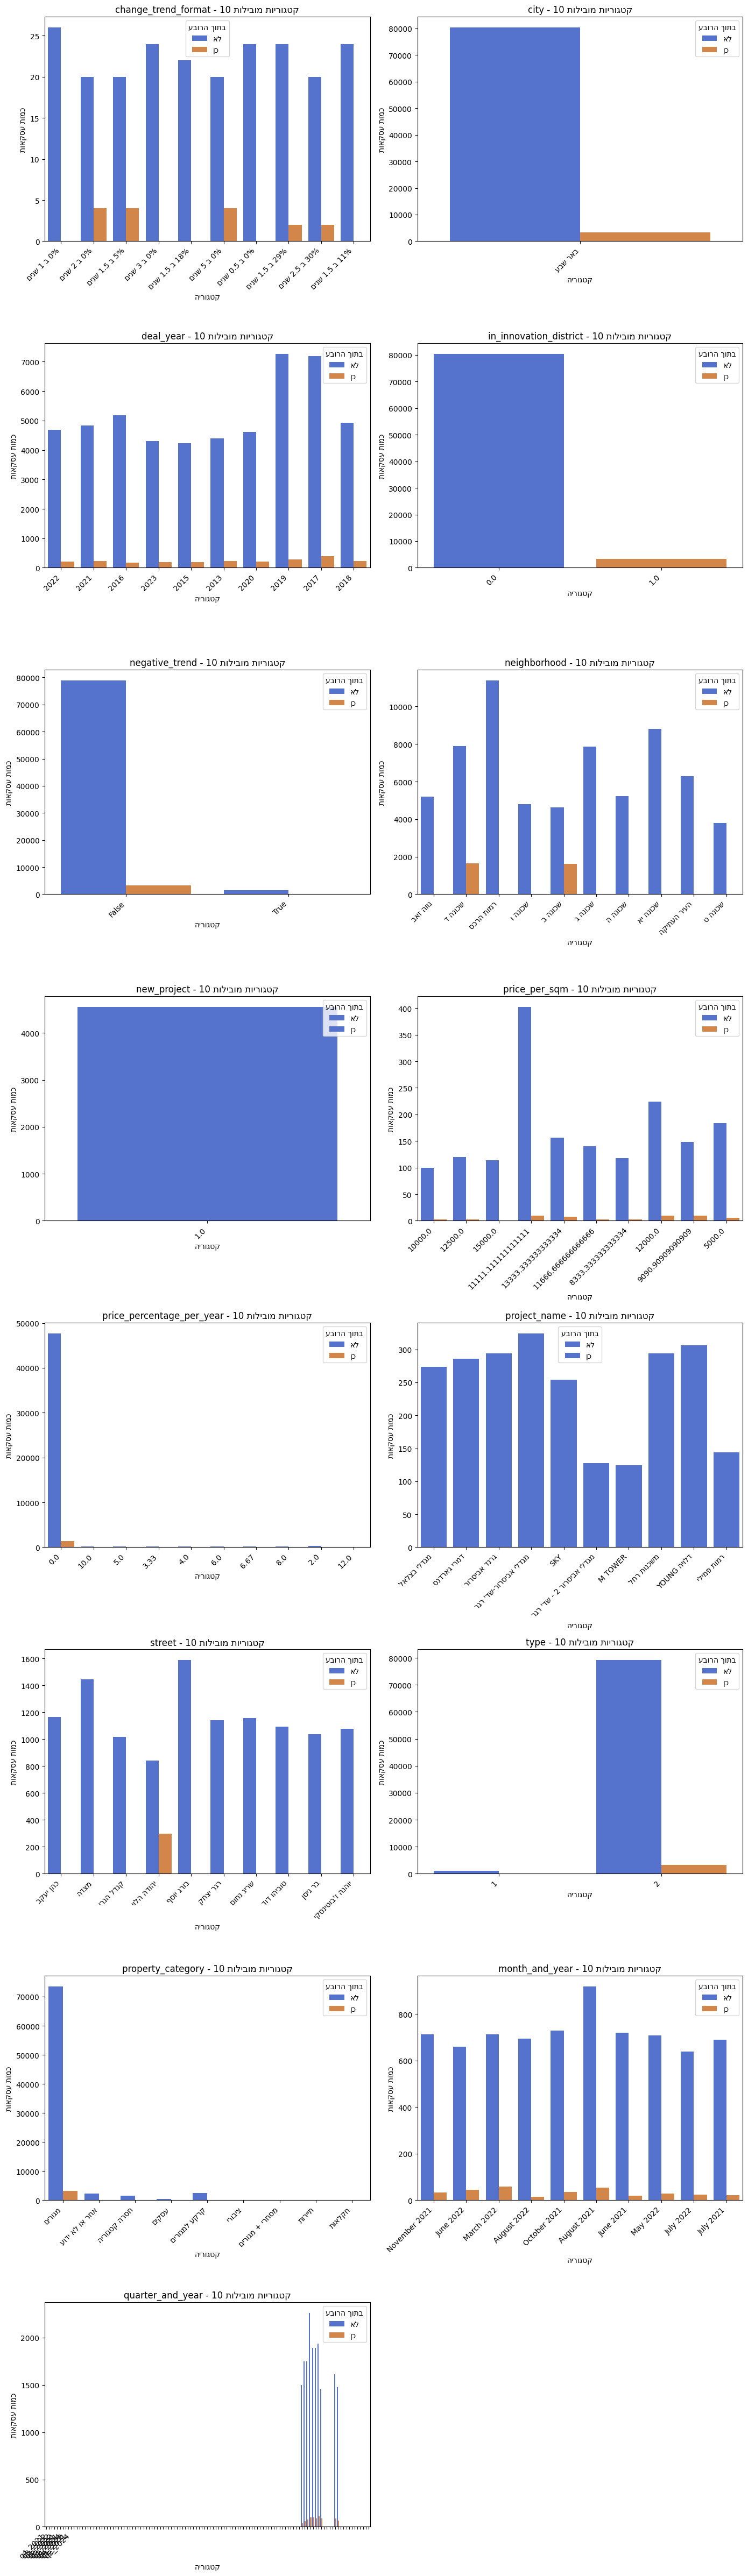

In [ ]:
# הגדרת פונט שתומך בעברית (אם יש צורך) ושימוש ב-rcParams להגדרות כלליות
plt.rcParams['axes.unicode_minus'] = False # מונע תקלות בסימני מינוס

def plot_validated_categorical_counts(df, cols_list, max_categories=10, name="Data"):
    cat_cols_to_plot = cat_cols_final
    num_plots = len(cat_cols_to_plot)

    ncols = 2
    nrows = math.ceil(num_plots / ncols)

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 6 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(cat_cols_to_plot):
        top_cats = df[col].value_counts().nlargest(max_categories).index
        df_plot = df[df[col].isin(top_cats)]

        sns.barplot(x=col, y=df_plot.index, ax=axes[i],
                    estimator=len,
                    hue='in_innovation_district',
                    data=df_plot,
                    palette={0: 'royalblue', 1: '#EA8333'},
                    errorbar=None)

        # תיקון העברית בכותרות ובתגיות
        axes[i].set_title(get_display(f"{col} - {max_categories} קטגוריות מובילות"), fontsize=12)
        axes[i].set_ylabel(get_display("כמות עסקאות"))
        axes[i].set_xlabel(get_display("קטגוריה"))

        # תיקון ספציפי לתוויות ציר ה-X - הופכים את הטקסט בנפרד
        ticks = [get_display(str(label)) for label in top_cats]
        axes[i].set_xticklabels(ticks, rotation=45, ha='right')

        axes[i].legend(title=get_display("בתוך הרובע"), labels=[get_display("לא"), get_display("כן")])

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_validated_categorical_counts(bs_data, cat_cols, name="Dataset")

### **7.3.**

Quarterly deal-count trend comparing inside vs. outside the Innovation District, and LOWESS-smoothed price trends against every numeric feature. Later in this part, two versions of the quarterly price-trend chart are plotted: one over the full history and one zoomed into the most recent ~20 quarters (5 years).

## **Bivariate Analysis**

Relationships between individual features and the price targets.

### **Barplots (Cateoric Vs. Label)**

Boxplots of `price_per_sqm` grouped by each categorical feature's top 10 values.

======= BIVARIATE ANALYSIS: Categorical vs price_per_sqm =======


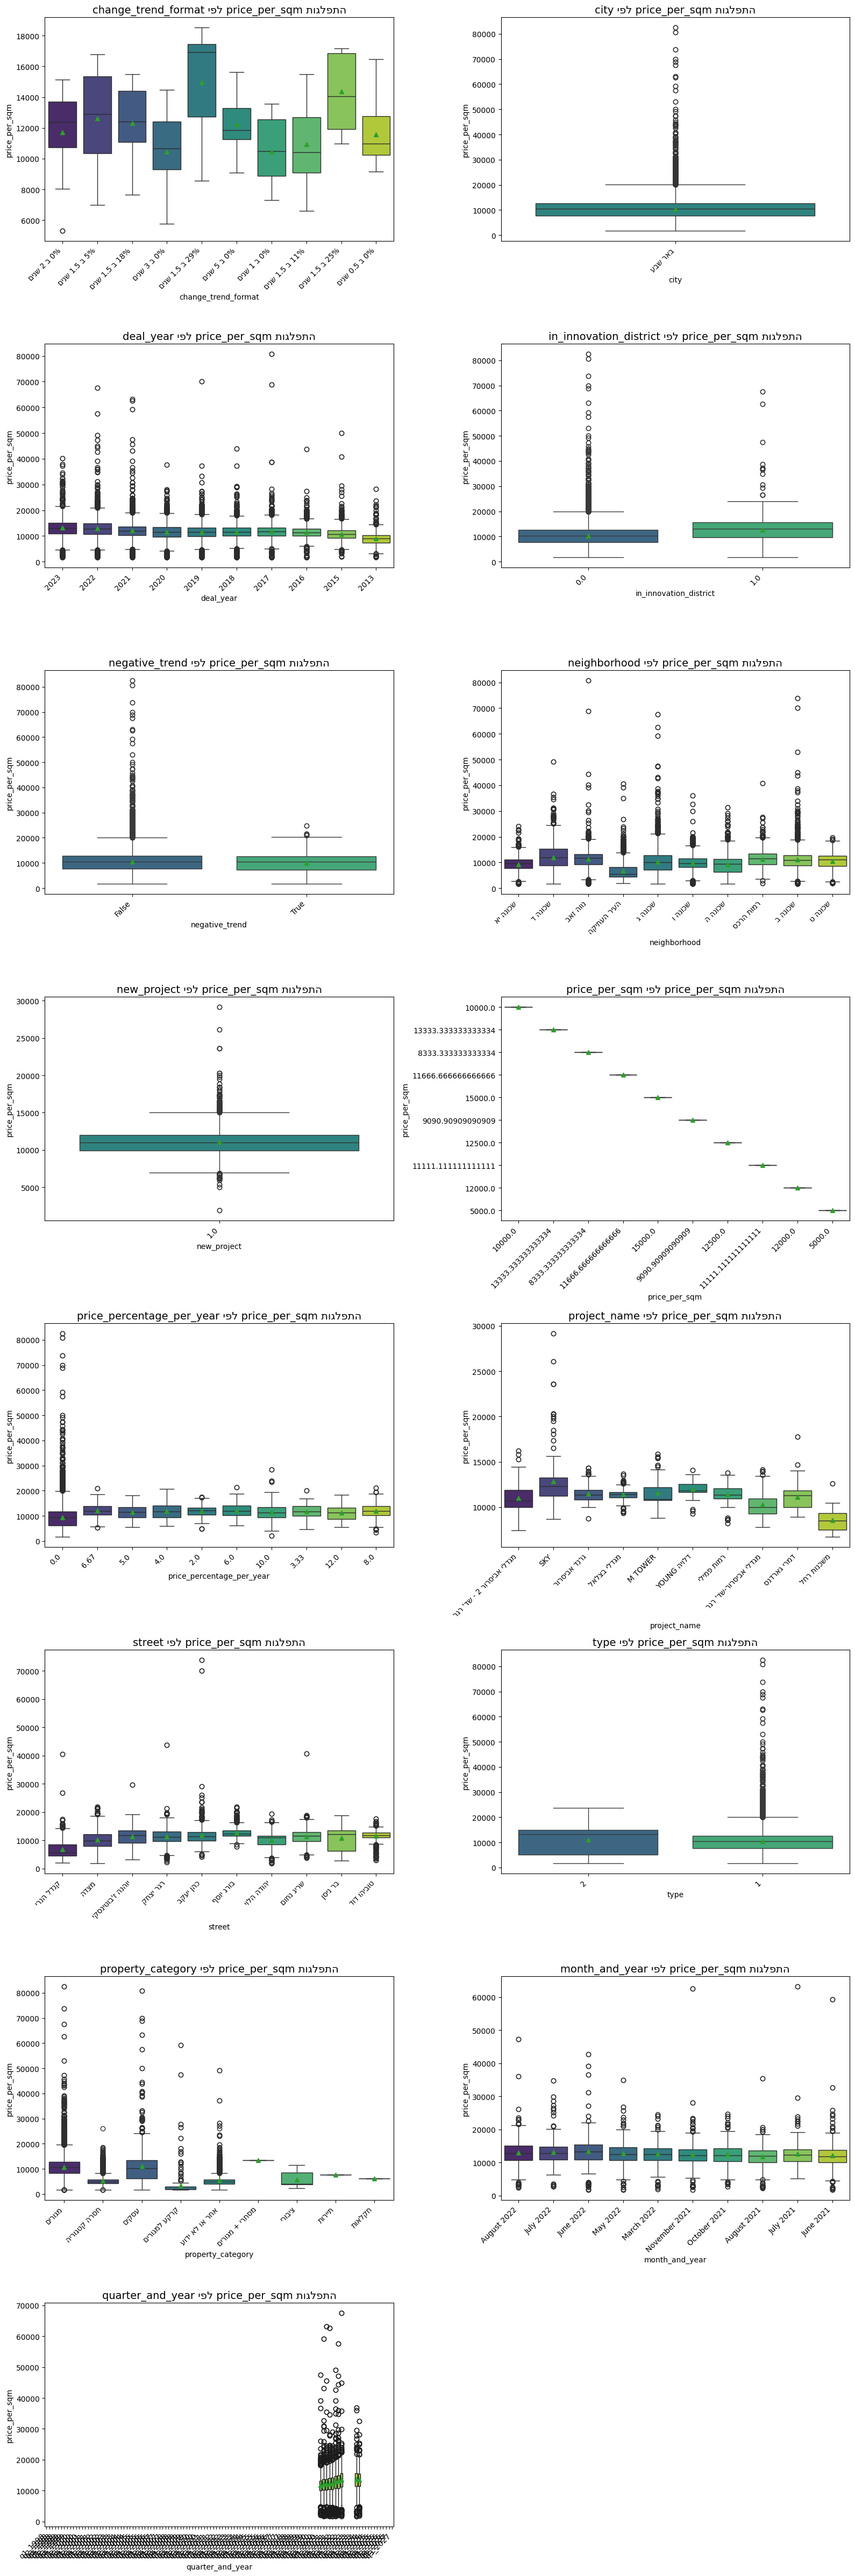

In [ ]:
def plot_categorical_vs_price(df, cat_columns, target_label='price_per_sqm'):
    # 1. סינון שורות שבהן המחיר למ"ר חסר (כפי שביקשת)
    df_plot = df.dropna(subset=[target_label]).copy()

    # 2. הגדרת מבנה הגרפים - 2 גרפים בכל שורה
    num_plots = len(cat_columns)
    ncols = 2
    nrows = math.ceil(num_plots / ncols)

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 6 * nrows))
    axes = axes.flatten()

    print(f"======= BIVARIATE ANALYSIS: Categorical vs {target_label} =======")

    for i, col in enumerate(cat_columns):
        # בדיקה שהעמודה קיימת בדאטהסט (בפורמט קטן)
        if col not in df_plot.columns:
            axes[i].set_title(f"Column '{col}' not found")
            continue

        # 3. הכנת הנתונים: לקיחת 10 הקטגוריות השכיחות ביותר למניעת עומס ויזואלי
        top_categories = df_plot[col].value_counts().nlargest(10).index
        temp_df = df_plot[df_plot[col].isin(top_categories)].copy()

        # 4. תיקון תצוגת עברית (RTL) עבור שמות הקטגוריות
        temp_df[col] = temp_df[col].apply(lambda x: get_display(str(x)) if pd.notnull(x) else x)

        # 5. יצירת ה-Boxplot
        sns.boxplot(x=col, y=target_label, data=temp_df, ax=axes[i], palette="viridis", showmeans=True)

        # עיצוב הכותרות והצירים (עם תיקון עברית)
        title_text = f"התפלגות {target_label} לפי {col}"
        axes[i].set_title(get_display(title_text), fontsize=14)
        axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')
        axes[i].set_xlabel(get_display(col))
        axes[i].set_ylabel(get_display(target_label))

    # הסרת ריבועים ריקים במידה ומספר הגרפים אינו זוגי
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

# הרצה על רשימת ה-cat_cols שלך (שגם הן באותיות קטנות)
plot_categorical_vs_price(bs_data, cat_cols_final)

### **7.4.**

Boxplots of numeric features against price, and time-trend comparisons of average price by quarter (Innovation District vs. rest of city vs. national).

### **Boxplots (Numeric Vs. Label)**

Line plots showing how price relates to each numeric feature, split by Innovation District status.

======= BIVARIATE ANALYSIS: Numeric Features vs price_per_sqm =======


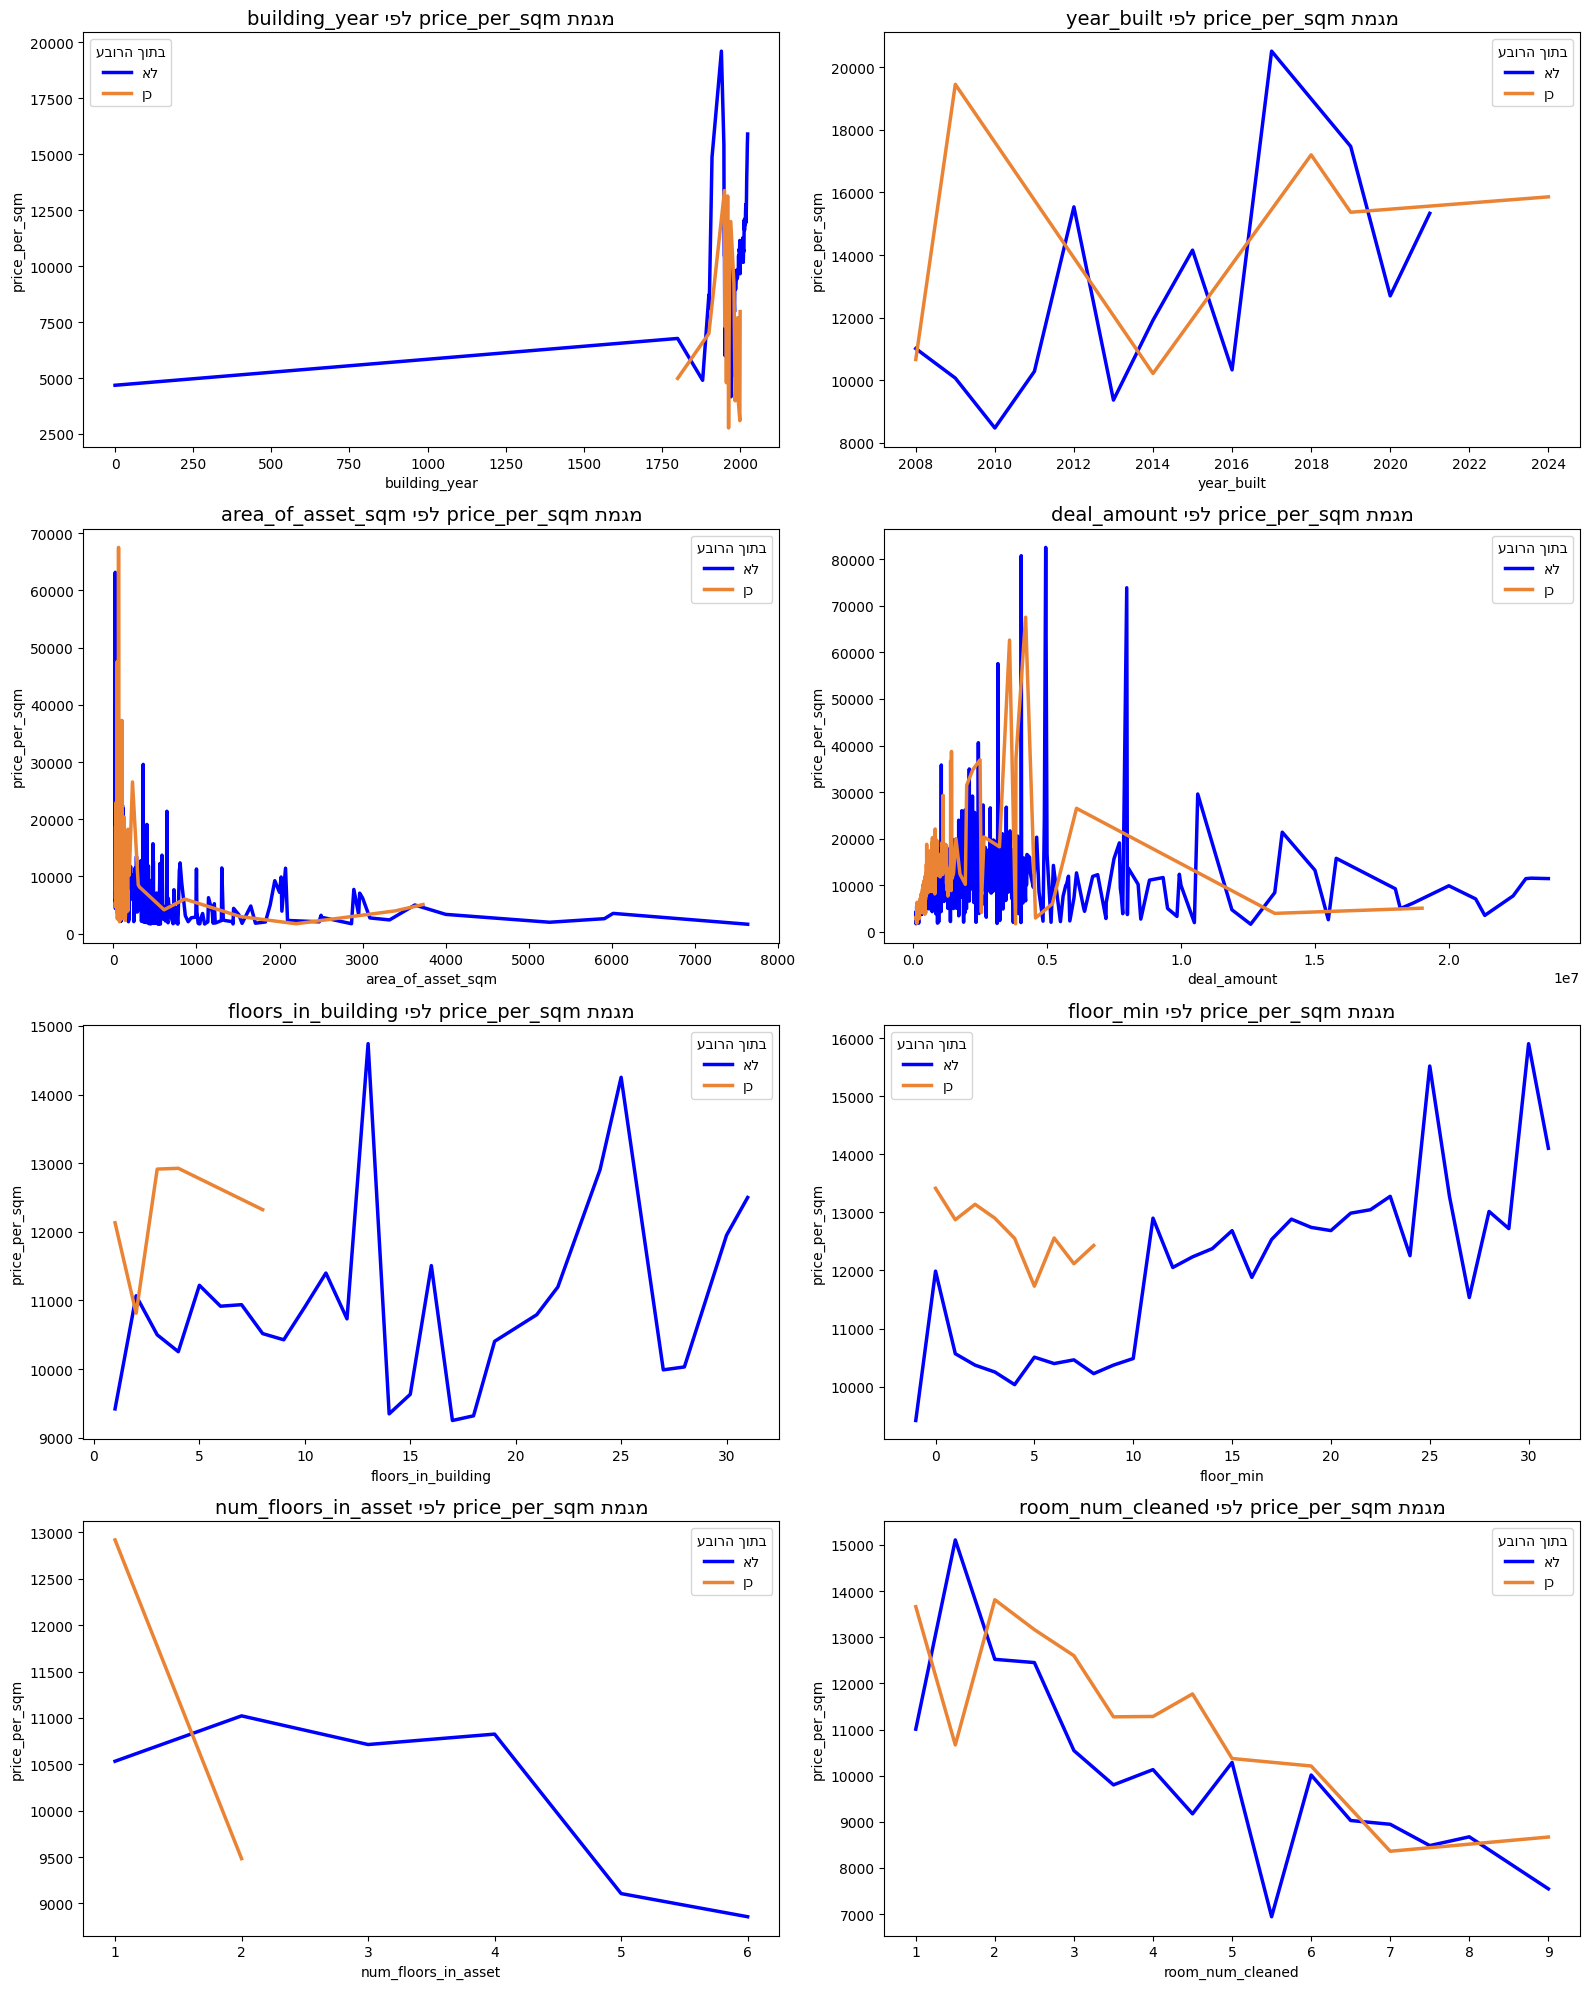

In [ ]:
# 1. סינון שורות שבהן הלייבל (price_per_sqm) חסר
target_label = 'price_per_sqm'
df_numeric_analysis = bs_data.dropna(subset=[target_label]).copy()

# 2. הגדרת רשימת המשתנים הנומריים
cols_to_plot = [col for col in num_cols_final if col != target_label]

# 3. הגדרת מבנה הגרפים
ncols = 2
nrows = math.ceil(len(cols_to_plot) / ncols)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 5 * nrows))
axes = axes.flatten()

print(f"======= BIVARIATE ANALYSIS: Numeric Features vs {target_label} =======")

for i, col in enumerate(cols_to_plot):
    # 4. יצירת גרף קו מגמה נקי ללא נקודות (הסרנו את marker='o')
    sns.lineplot(x=col, y=target_label,
                 hue='in_innovation_district',
                 data=df_numeric_analysis,
                 ax=axes[i],
                 palette={0: 'blue', 1: '#EA8333'},
                 linewidth=2.5,
                 errorbar=None) # מציג רק את הקו החלק

    # 5. עיצוב בעברית
    title_text = f"מגמת {target_label} לפי {col}"
    axes[i].set_title(get_display(title_text), fontsize=14)
    axes[i].set_xlabel(get_display(col))
    axes[i].set_ylabel(get_display(target_label))
    axes[i].legend(title=get_display("בתוך הרובע"), labels=[get_display("לא"), get_display("כן")])

# הסרת תתי-גרפים ריקים
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### **7.5.**

Distribution of each numeric feature split by Innovation District status, to check for structural differences (e.g. do Innovation District apartments tend to be smaller or newer?).

### **Boxplots - Numeric Cols Distribution**

Same idea as the earlier numeric histograms in Part 3, but restricted to the final cleaned feature set and explicitly grouped by Innovation District status.

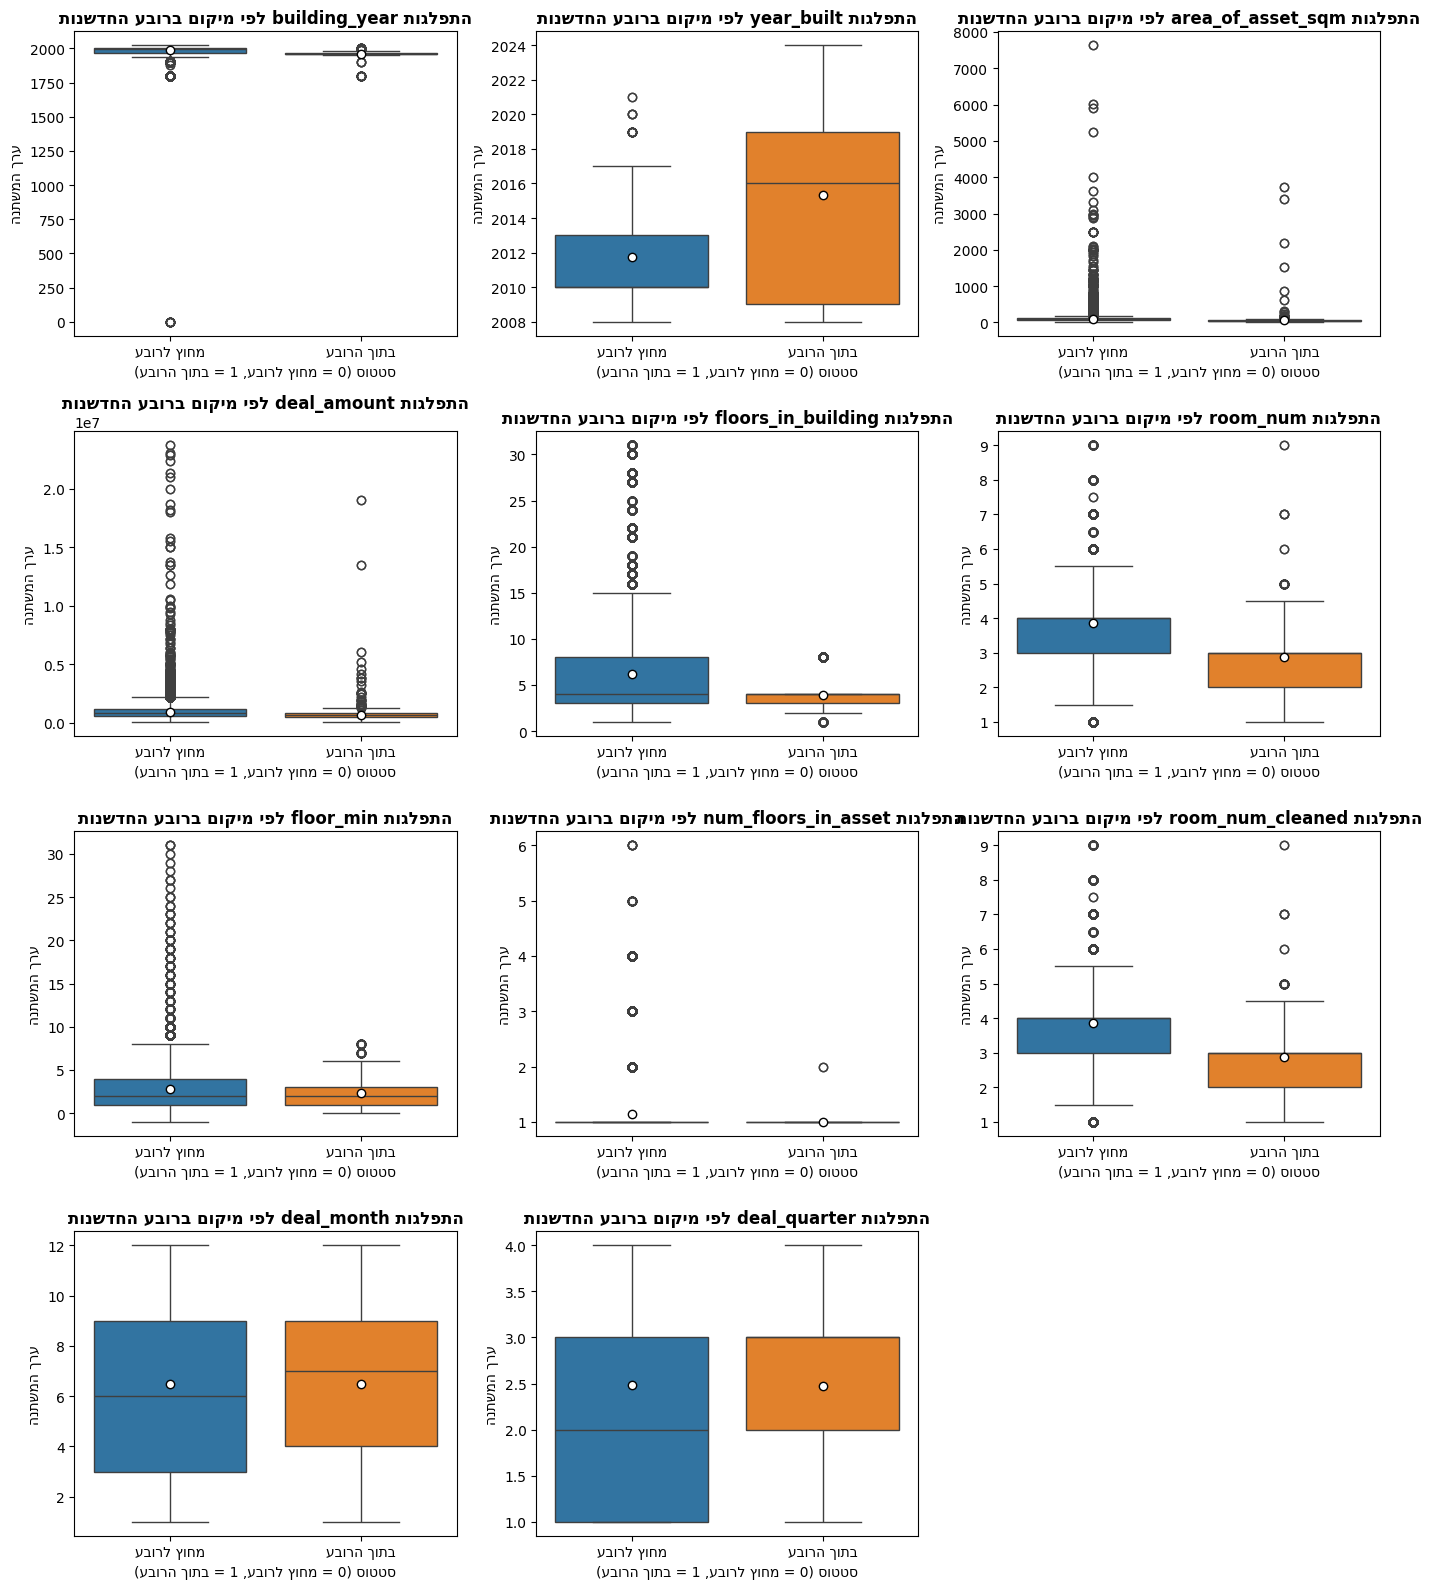

In [ ]:
def plot_innovation_boxplots_robust(
    df, columns, group_col="in_innovation_district"
):
    """יוצר תרשימי קופסה להשוואה בין הרובע לשאר העיר.

    כולל תמיכה מלאה בכל סוגי הנתונים בעמודת המיקום (טקסט, שלם, עשרוני).
    """
    # חישוב דינמי של גודל הלוח
    valid_cols = [col for col in columns if col in df.columns]
    num_plots = len(valid_cols)
    ncols = 3
    nrows = math.ceil(num_plots / ncols)

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 4 * nrows))
    axes = axes.flatten()

    # פלטת צבעים מורחבת וחסינה לכל סוגי הטיפוסים (שלמים, עשרוניים ומחרוזות)
    custom_palette = {
        # מחוץ לרובע (כחול)
        0: "#1f77b4",
        0.0: "#1f77b4",
        "0": "#1f77b4",
        "0.0": "#1f77b4",
        # בתוך הרובע (כתום)
        1: "#FF7F0E",
        1.0: "#FF7F0E",
        "1": "#FF7F0E",
        "1.0": "#FF7F0E",
    }

    for i, col in enumerate(valid_cols):
        # הגנה: בדיקה אם יש נתונים לצייר
        if df[col].dropna().empty:
            axes[i].set_title(
                get_display(f"{col}\n(אין נתונים זמינים)"), color="red"
            )
            axes[i].axis("off")
            continue

        # יצירת ה-Boxplot עם הפלטה המורחבת
        sns.boxplot(
            x=group_col,
            y=col,
            data=df,
            ax=axes[i],
            palette=custom_palette,  # שימוש בפלטה המורחבת שמונעת את השגיאה
            showmeans=True,
            meanprops={
                "marker": "o",
                "markerfacecolor": "white",
                "markeredgecolor": "black",
            },
        )

        # עיצוב וכותרות בעברית תקנית
        axes[i].set_title(
            get_display(f"התפלגות {col} לפי מיקום ברובע החדשנות"),
            fontsize=12,
            fontweight="bold",
        )
        axes[i].set_ylabel(get_display("ערך המשתנה"))
        axes[i].set_xlabel(get_display("סטטוס (0 = מחוץ לרובע, 1 = בתוך הרובע)"))

        # הגדרת תוויות לציר ה-X
        axes[i].set_xticklabels([get_display("מחוץ לרובע"), get_display("בתוך הרובע")])

    # הסרת ריבועים עודפים
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


# הרצה מחדש על רשימת ה-num_cols המעודכנת שלך
plot_innovation_boxplots_robust(bs_data, num_cols)

# **PART 8**

Final exports: saving the cleaned dataset(s) for use outside this notebook. Note that one export (a filtered subset, `dataset_filtered.csv`) is actually triggered earlier, at the end of Part 7 — consider moving that cell down here for consistency next time you edit the notebook.

### **8.1. Exporting Visualization Artifacts**

No cell currently saves individual chart images to disk — charts are only displayed inline. Add `plt.savefig(...)` calls inside the relevant plotting functions if you need standalone image files (e.g. for a report).

In [ ]:
import os
import shutil

FIGURES_DIR = 'figures'
os.makedirs(FIGURES_DIR, exist_ok=True)

def save_last_figure(name):
    """Save whichever figure is currently active. Must be called in the same cell as the
    plotting call, right after it — Jupyter/Colab closes figures once a cell finishes running."""
    path = os.path.join(FIGURES_DIR, f'{name}.png')
    plt.gcf().savefig(path, dpi=150, bbox_inches='tight')
    print(f'💾 saved {path}')

# --- Re-render every Part 7 chart and save it, in the same order they first appeared ---

plot_safe_correlation_matrix_price_sqm(bs_data, num_cols_final)
save_last_figure('7_1_1_correlation_price_per_sqm')

plot_safe_correlation_matrix_deal_amount(bs_data, num_cols_final)
save_last_figure('7_1_2_correlation_deal_amount')

plot_validated_dealamount_distributions(bs_data, num_cols_final, name="Validated_Dataset")
save_last_figure('7_2_1_histograms_numeric_by_district')

plot_comparative_quarterly_counts(bs_data)
save_last_figure('7_2_2_quarterly_deal_counts')

plot_all_numeric_lowess_trends(bs_data, sample_60k, num_cols_final, frac=0.3)
save_last_figure('7_2_3_lowess_trends')

plot_two_separate_trends_fixed(bs_data, period_col='month_and_year', periods_back=24)
save_last_figure('7_2_4_monthly_trend_innovation_district')

plot_two_separate_trends_fixed(bs_data, period_col='quarter_and_year', periods_back=8)
save_last_figure('7_2_5_quarterly_trend_innovation_district')

plot_professional_quarterly_trends_final(dataset_cleaned, target_label='deal_amount', df_national=sample_60k)
save_last_figure('7_2_6_quarterly_deal_amount_full_history')

plot_professional_quarterly_trends_final(dataset_cleaned, target_label='price_per_sqm', df_national=sample_60k)
save_last_figure('7_2_7_quarterly_price_per_sqm_full_history')

plot_professional_quarterly_trends_final_5_years(dataset_cleaned, target_label='deal_amount', df_national=sample_60k)
save_last_figure('7_2_8_quarterly_deal_amount_last_5_years')

plot_professional_quarterly_trends_final_5_years(dataset_cleaned, target_label='price_per_sqm', df_national=sample_60k)
save_last_figure('7_2_9_quarterly_price_per_sqm_last_5_years')

plot_validated_categorical_counts(bs_data, cat_cols, name="Dataset")
save_last_figure('7_2_10_countplots_categorical')

plot_categorical_vs_price(bs_data, cat_cols_final)
save_last_figure('7_3_1_barplots_categorical_vs_price')

# the bivariate numeric-vs-price lineplot block (currently inline code, not a function, in 7.4)
target_label = 'price_per_sqm'
df_numeric_analysis = bs_data.dropna(subset=[target_label]).copy()
cols_to_plot = [col for col in num_cols_final if col != target_label]
ncols = 2
nrows = math.ceil(len(cols_to_plot) / ncols)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 5 * nrows))
axes = axes.flatten()
for i, col in enumerate(cols_to_plot):
    sns.lineplot(x=col, y=target_label, hue='in_innovation_district', data=df_numeric_analysis,
                 ax=axes[i], palette={0: 'blue', 1: '#EA8333'}, linewidth=2.5, errorbar=None)
    axes[i].set_title(get_display(f"מגמת {target_label} לפי {col}"), fontsize=14)
    axes[i].set_xlabel(get_display(col))
    axes[i].set_ylabel(get_display(target_label))
    axes[i].legend(title=get_display("בתוך הרובע"), labels=[get_display("לא"), get_display("כן")])
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()
save_last_figure('7_4_1_lineplots_numeric_vs_price')

plot_innovation_boxplots_robust(bs_data, num_cols)
save_last_figure('7_5_1_boxplots_numeric_distribution')

print(f"\n✅ {len(os.listdir(FIGURES_DIR))} figures saved to '{FIGURES_DIR}/'")

# Charts are retained inline and optionally saved locally in the figures directory.

### **8.3. Pipeline Documentation**

To re-run this analysis with separately authorized input files: update the file paths (cells under 2.2/2.3/2.6), the `cutoff` date (2.3), and the valid year range (2.4); then run all cells top to bottom. Re-check the column-mapping validation output (cells under 2.5.1/2.6.2) and the property-type mapping printout (4.3.2) for anything new that needs to be added to those dictionaries.

In [ ]:
from datetime import datetime

report_lines = [
    "# Pipeline Run Report",
    f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}",
    "",
    "## Row counts at each stage",
    f"- Beer Sheva old file (`dataset_original`): {len(dataset_original):,} rows",
    f"- Beer Sheva updated file after cutoff-fix & year filter (`updated_data`): {len(updated_data):,} rows",
    f"- Unified Beer Sheva (`unified_df`): {len(unified_df):,} rows",
    f"- Multi-city merged (`multi_city_df`): {len(multi_city_df):,} rows",
    f"- Final cleaned dataset (`dataset_cleaned`): {len(dataset_cleaned):,} rows, {dataset_cleaned.shape[1]} cols",
    f"- Beer-Sheva-only analysis subset (`bs_data`): {len(bs_data):,} rows",
    "",
    "## Checklist before re-running on a new dataset",
    "- [ ] File paths in 2.2 / 2.3 / 2.6 point to the new files",
    f"- [ ] `cutoff` date in 2.3 (currently {cutoff.date()}) matches the new file's actual download date",
    "- [ ] Valid year range in 2.4 matches the new data's expected years",
    "- [ ] Property-type mapping (4.3.2) — check console output for any unmapped categories",
    "- [ ] Column-mapping validation (2.5.1 / 2.6.2) — check `validate_columns` output for anything missing",
    "",
    "## Outputs produced by this run",
    f"- `{FIGURES_DIR}/` — chart images from Part 7",
]

report_text = '\n'.join(report_lines)
print(report_text)

with open('PIPELINE_REPORT.md', 'w', encoding='utf-8') as f:
    f.write(report_text)

# Report is written locally; no automatic download.